# Adversarial Generators on Four Data Types: Points, Retinas, Network Flows and Sketches

This notebook holds every model, figure and number used in the accompanying report. It is organised as six stations:

| Station | Brief part | Content |
|---|---|---|
| A | Setup | configuration, seeds, device, shared plotting and metric tools |
| B | Part 1 | tutorial sine GAN, a seven-mode Gaussian mixture, architecture variants |
| C | Part 2.1 | OCTMNIST retinal scans: DCGAN, Inception FID/KID, domain FID, AC-GAN extension |
| D | Part 2.2 | CICIDS 2017 flows: conditional WGAN-GP on Wednesday traffic, all-days extension |
| E | Part 2.3 | QuickDraw birthday cake DCGAN, plus star, house and cat extension |
| F | Summary | one table that gathers the headline metrics from every station |

**How to run.** Run all cells top to bottom. Set the environment variable `GAN_SMOKE=1` (or edit `SMOKE` below) for a quick functional check with tiny epochs and subsets; the numbers from a smoke run are not meaningful. The full run trains every model from scratch with fixed seeds. Device is chosen automatically (CUDA, then Apple MPS, then CPU), so the same notebook runs locally and on Colab. GPU kernels are not bit-for-bit deterministic, so a rerun on different hardware gives slightly different values.

## Station A: setup and shared tools

In [1]:
# Install any dependency that is missing (useful on a fresh Colab runtime, which lacks torch-fidelity and torchmetrics).
import importlib, subprocess, sys
for pkg, mod in [("torch-fidelity", "torch_fidelity"), ("torchmetrics", "torchmetrics"), ("torchvision", "torchvision"),
                 ("scikit-learn", "sklearn"), ("scipy", "scipy"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

In [2]:
import os, math, json, time, random, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torch_fidelity  # imported before torchmetrics so its availability flag is cached as True
from torchmetrics.image.fid import NoTrainInceptionV3
from torchvision.utils import make_grid
from scipy import linalg, stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score, classification_report

warnings.filterwarnings("ignore", category=UserWarning)
# Apple Accelerate BLAS raises spurious floating-point flags on large float64 matmuls; results are unaffected.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
# ks_2samp falls back from its exact to its asymptotic p-value on large samples; only the statistic is used here.
warnings.filterwarnings("ignore", message=".*Exact calculation unsuccessful.*")

# SMOKE=True gives a fast functional check; SMOKE=False is the full experiment used in the report.
SMOKE = os.environ.get("GAN_SMOKE", "0") == "1"

ROOT = Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
OUT = ROOT / "outputs"
for p in (DATA / "medmnist", DATA / "quickdraw", DATA / "cicids", FIG, OUT / "checkpoints"):
    p.mkdir(parents=True, exist_ok=True)

# One configuration dict for the whole notebook; every station reads its settings from here.
CFG = {
    "seed": 42,
    "p1": {"n_points": 1024, "batch": 32, "lr": 1e-3, "latent": 2,
           "epochs_sine": 60 if SMOKE else 2000,
           "n_hex": 2048, "epochs_hex": 30 if SMOKE else 1000,
           "n_eval": 1000, "extra_seeds": [7, 2024]},
    "img": {"z_dim": 100, "width": 64, "batch": 128, "lr": 2e-4, "betas": (0.5, 0.999),
            "real_label": 0.9},
    "oct": {"epochs": 1 if SMOKE else 12, "ac_epochs": 1 if SMOKE else 10,
            "probe_epochs": 1 if SMOKE else 6, "n_train_cap": 4000 if SMOKE else None,
            "n_fid": 500 if SMOKE else 10000, "n_per_class_ac": 100 if SMOKE else 1000},
    "cic": {"smoke_frac": 0.05 if SMOKE else None, "iters": 150 if SMOKE else 8000,
            "iters_ext": 150 if SMOKE else 6000, "n_critic": 5, "batch": 256, "gp": 10.0,
            "lr": 1e-4, "betas": (0.5, 0.9), "z_dim": 64, "hidden": 256,
            "eval_n": 2000 if SMOKE else 20000, "tsne_n": 300 if SMOKE else 2000,
            "tstr_per_class": 300 if SMOKE else 4000, "family_cap": 2000 if SMOKE else 12000},
    "qd": {"n_train": 3000 if SMOKE else 60000, "n_ref": 1000 if SMOKE else 10000,
           "epochs": 2 if SMOKE else 15, "track_epochs": [1, 2] if SMOKE else [1, 5, 10, 15],
           "n_track": 500 if SMOKE else 3000, "ext_classes": ["star", "house", "cat"],
           "ext_train": 2000 if SMOKE else 30000, "ext_ref": 500 if SMOKE else 5000,
           "ext_epochs": 1 if SMOKE else 10},
}

def pick_compute_device():
    """Return the fastest available torch device: CUDA, then Apple MPS, then CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def pin_every_seed(seed):
    """Seed Python, NumPy and torch (all devices) so each station starts from a known state."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

DEVICE = pick_compute_device()
CPU = torch.device("cpu")   # the tiny 2D and tabular MLPs train faster on CPU than on a GPU
pin_every_seed(CFG["seed"])
print("SMOKE:", SMOKE, "| image device:", DEVICE, "| torch", torch.__version__)

SMOKE: False | image device: mps | torch 2.13.0


In [3]:
# Shared style ("heron-7" palette) and figure saving helper.
HUE = {"real": "#2E4057", "fake": "#D1495B", "gold": "#EDAE49", "petrol": "#00798C",
       "sage": "#66A182", "plum": "#7A4E7E", "grey": "#9AA0A6"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.titlesize": 11,
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[HUE[k] for k in ("real", "fake", "gold", "petrol", "sage", "plum")]),
})

def release_accelerator():
    """Return cached GPU/MPS memory to the system between stations."""
    import gc; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()

def stamp_figure(fig, name):
    """Save a figure to figures/<name>.png with tight bounds and show it inline."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

def store_json(obj, name):
    """Write a metrics dictionary to outputs/<name>.json."""
    with open(OUT / f"{name}.json", "w") as fh:
        json.dump(obj, fh, indent=2, default=float)

# Wall-clock timer per station, saved to outputs/run_meta.json at the end.
CLOCK = {}
def station_clock(name, start=None):
    """Call with no start to begin timing; call with the returned start to record minutes."""
    if start is None:
        return time.time()
    CLOCK[name] = round((time.time() - start) / 60, 2)
    print(f"[{name}] {CLOCK[name]} min")

In [4]:
# Image tools shared by Stations C and E.
def to_pixels(x):
    """Map generator output in [-1, 1] to uint8 pixels in [0, 255] on the CPU."""
    return ((x.detach().float().cpu() + 1) * 127.5).round().clamp(0, 255).to(torch.uint8)

def ink_grid(ax, imgs_u8, nrow=8, title=None, invert=False):
    """Draw a grid of uint8 images [N,1,H,W] on an axis; invert=True shows sketches as dark ink on white."""
    g = make_grid(imgs_u8.float() / 255.0, nrow=nrow, padding=1, pad_value=1.0)[0].numpy()
    ax.imshow(1 - g if invert else g, cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title)

_INCEPTION = {}
def inception_bank(imgs_u8, batch=200):
    """2048-d Inception-v3 pool features (the FID network) for uint8 images [N,1,28,28].

    Grey images are repeated to three channels; the network resizes to 299x299 internally.
    Falls back to CPU if the accelerator cannot run the network.
    """
    if "net" not in _INCEPTION:
        net = NoTrainInceptionV3(name="inception-v3-compat", features_list=["2048"]).eval()
        try:
            net = net.to(DEVICE); dev = DEVICE
            with torch.no_grad():
                net(torch.zeros(2, 3, 28, 28, dtype=torch.uint8, device=DEVICE))
        except Exception as err:  # pragma: no cover - only on unusual backends
            print("Inception on CPU:", err); net = net.to(CPU); dev = CPU
        _INCEPTION.update(net=net, dev=dev)
    net, dev = _INCEPTION["net"], _INCEPTION["dev"]
    feats = []
    with torch.no_grad():
        for i in range(0, len(imgs_u8), batch):
            x = imgs_u8[i:i + batch].repeat(1, 3, 1, 1).to(dev)
            feats.append(net(x).cpu().double())
    return torch.cat(feats).numpy()

def frechet_from_bank(a, b):
    """Frechet distance between two feature banks (rows are samples)."""
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
    if not np.isfinite(covmean).all():  # near-singular covariances: add a small ridge, as in the reference FID code
        ridge = np.eye(len(s1)) * 1e-6
        covmean, _ = linalg.sqrtm((s1 + ridge) @ (s2 + ridge), disp=False)
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

def kid_from_bank(a, b, n_sub=50, sub_size=1000, seed=0):
    """Kernel Inception Distance: unbiased MMD^2 with a cubic polynomial kernel, mean and std over subsets."""
    rng = np.random.default_rng(seed)
    m = min(sub_size, len(a), len(b)); d = a.shape[1]; vals = []
    for _ in range(n_sub):
        x = a[rng.choice(len(a), m, replace=False)]; y = b[rng.choice(len(b), m, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3; kyy = (y @ y.T / d + 1) ** 3; kxy = (x @ y.T / d + 1) ** 3
        mmd = ((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) + (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
               - 2 * kxy.mean())
        vals.append(mmd)
    return float(np.mean(vals)), float(np.std(vals))

In [5]:
# The shared DCGAN builder used for OCT (Station C) and QuickDraw (Station E).
class ConvForger(nn.Module):
    """DCGAN generator for 28x28 grey images: z (optionally + class embedding) -> 7x7 -> 14x14 -> 28x28."""
    def __init__(self, z_dim=100, width=64, n_classes=0):
        super().__init__()
        self.n_classes = n_classes
        self.embed = nn.Embedding(n_classes, n_classes * 4) if n_classes else None
        cin = z_dim + (n_classes * 4 if n_classes else 0)
        self.body = nn.Sequential(
            nn.ConvTranspose2d(cin, width * 4, 7, 1, 0, bias=False), nn.BatchNorm2d(width * 4), nn.ReLU(True),
            nn.ConvTranspose2d(width * 4, width * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(width * 2), nn.ReLU(True),
            nn.ConvTranspose2d(width * 2, width, 4, 2, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU(True),
            nn.Conv2d(width, 1, 3, 1, 1), nn.Tanh())

    def forward(self, z, y=None):
        if self.embed is not None:
            z = torch.cat([z, self.embed(y)], 1)
        return self.body(z[:, :, None, None])

class ConvJudge(nn.Module):
    """DCGAN discriminator: strided convs + LeakyReLU, a real/fake logit and an optional class head (AC-GAN)."""
    def __init__(self, width=64, n_classes=0):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, width, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(width, width * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(width * 2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(width * 2, width * 4, 3, 2, 1, bias=False), nn.BatchNorm2d(width * 4), nn.LeakyReLU(0.2, True),
            nn.Flatten())
        self.src = nn.Linear(width * 4 * 16, 1)
        self.cls = nn.Linear(width * 4 * 16, n_classes) if n_classes else None

    def forward(self, x):
        h = self.body(x)
        return self.src(h).squeeze(1), (self.cls(h) if self.cls is not None else None)

def radford_weight_start(m):
    """DCGAN weight initialisation: N(0, 0.02) for conv weights, N(1, 0.02) for BatchNorm scales."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def pair_conv_duelists(n_classes=0):
    """Build a fresh generator/discriminator pair on DEVICE from CFG['img']; n_classes>0 gives an AC-GAN pair."""
    c = CFG["img"]
    g = ConvForger(c["z_dim"], c["width"], n_classes).to(DEVICE)
    d = ConvJudge(c["width"], n_classes).to(DEVICE)
    g.apply(radford_weight_start); d.apply(radford_weight_start)
    return g, d

def duel_on_images(images, labels, forger, judge, epochs, n_classes=0, epoch_hook=None, seed=42):
    """Train a DCGAN (n_classes=0) or AC-GAN (n_classes>0) on images in [-1,1].

    Returns per-iteration logs (D loss, G loss, mean D(x), mean D(G(z))) and the fixed-noise
    sample grid after every epoch. epoch_hook(epoch, forger) runs after each epoch (used for FID tracking).
    """
    c = CFG["img"]; bs = c["batch"]; n = len(images)
    gen = torch.Generator().manual_seed(seed)
    opt_g = torch.optim.Adam(forger.parameters(), lr=c["lr"], betas=c["betas"])
    opt_d = torch.optim.Adam(judge.parameters(), lr=c["lr"], betas=c["betas"])
    bce, ce = nn.BCEWithLogitsLoss(), nn.CrossEntropyLoss()
    fixed_z = torch.randn(64, c["z_dim"], generator=gen).to(DEVICE)
    fixed_y = (torch.arange(64) % n_classes).to(DEVICE) if n_classes else None
    logs, snaps = [], []
    for ep in range(1, epochs + 1):
        perm = torch.randperm(n, generator=gen).to(DEVICE)
        ep_log = []
        for i in range(0, n - bs + 1, bs):
            idx = perm[i:i + bs]
            real = images[idx]; b = real.shape[0]
            z = torch.randn(b, c["z_dim"], device=DEVICE)
            yf = torch.randint(0, n_classes, (b,), device=DEVICE) if n_classes else None
            fake = forger(z, yf)
            # Discriminator step: fake is detached so no gradient reaches the generator here.
            opt_d.zero_grad(set_to_none=True)
            sr, cr = judge(real); sf, cf = judge(fake.detach())
            loss_d = bce(sr, torch.full_like(sr, c["real_label"])) + bce(sf, torch.zeros_like(sf))
            if n_classes:
                loss_d = loss_d + ce(cr, labels[idx]) + ce(cf, yf)
            loss_d.backward(); opt_d.step()
            # Generator step: discriminator weights are frozen and its optimiser is not stepped.
            for p in judge.parameters():
                p.requires_grad_(False)
            opt_g.zero_grad(set_to_none=True)
            sg, cg = judge(fake)
            loss_g = bce(sg, torch.ones_like(sg)) + (ce(cg, yf) if n_classes else 0.0)
            loss_g.backward(); opt_g.step()
            for p in judge.parameters():
                p.requires_grad_(True)
            ep_log.append(torch.stack([loss_d.detach(), loss_g.detach(),
                                       torch.sigmoid(sr).mean().detach(), torch.sigmoid(sf).mean().detach()]))
        logs.append(torch.stack(ep_log).cpu())
        forger.eval()
        with torch.no_grad():
            snaps.append(to_pixels(forger(fixed_z, fixed_y)))
        if epoch_hook is not None:
            epoch_hook(ep, forger)
        forger.train()
        last = logs[-1].mean(0).tolist()
        print(f"epoch {ep:2d}/{epochs}  D {last[0]:.3f}  G {last[1]:.3f}  D(x) {last[2]:.2f}  D(G(z)) {last[3]:.2f}")
    log = pd.DataFrame(torch.cat(logs).numpy(), columns=["loss_d", "loss_g", "d_real", "d_fake"])
    return log, snaps

def mint_images(forger, n, labels=None, batch=500):
    """Sample n uint8 images from a trained generator (eval mode); labels gives the class per sample."""
    forger.eval(); out = []
    with torch.no_grad():
        for i in range(0, n, batch):
            b = min(batch, n - i)
            z = torch.randn(b, CFG["img"]["z_dim"], device=DEVICE)
            y = labels[i:i + b].to(DEVICE) if labels is not None else None
            out.append(to_pixels(forger(z, y)))
    forger.train()
    return torch.cat(out)

def plot_duel_curves(log, title, name, smooth=50):
    """Two panels: smoothed D and G losses, and smoothed mean D(x) and D(G(z)), per iteration."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    r = log.rolling(smooth, min_periods=1).mean()
    ax[0].plot(r.loss_d, label="discriminator", color=HUE["real"]); ax[0].plot(r.loss_g, label="generator", color=HUE["fake"])
    ax[0].set(xlabel="iteration", ylabel="loss", title=f"{title}: losses ({smooth}-iteration mean)"); ax[0].legend()
    ax[1].plot(r.d_real, label="D(x) real", color=HUE["petrol"]); ax[1].plot(r.d_fake, label="D(G(z)) fake", color=HUE["gold"])
    ax[1].set(xlabel="iteration", ylabel="mean discriminator output", ylim=(0, 1), title=f"{title}: discriminator outputs"); ax[1].legend()
    fig.tight_layout(); stamp_figure(fig, name)

def plot_snap_progress(snaps, title, name, invert=False):
    """Show the fixed-noise grid at the first, middle and last epoch."""
    picks = sorted(set([0, len(snaps) // 2, len(snaps) - 1]))
    fig, ax = plt.subplots(1, len(picks), figsize=(3.6 * len(picks), 3.8))
    ax = np.atleast_1d(ax)
    for a, k in zip(ax, picks):
        ink_grid(a, snaps[k][:36], nrow=6, title=f"epoch {k + 1}", invert=invert)
    fig.suptitle(title); fig.tight_layout(); stamp_figure(fig, name)

## Station B: Part 1, GANs from scratch on 2D data

### B1. Reproducing the tutorial sine-wave GAN

The tutorial specification is kept as written: seed 42, 1,024 pairs with x drawn uniformly on [0, 2π] and y = sin(x), shuffled batches of 32, a discriminator 2-256-128-64-1 with ReLU, dropout 0.3 and a sigmoid output, a generator 2-16-32-2 with ReLU, binary cross-entropy, Adam with learning rate 0.001 for both networks, 2,000 epochs and 1,000 generated samples.

Four corrections to the tutorial loop are applied. None of them changes the experiment; they remove fragile or incorrect training logic:

1. labels and latent vectors are sized from the current batch (`real.shape[0]`), not a fixed 32;
2. generator output is detached in the discriminator step, so that step does not build gradients for the generator;
3. the discriminator is frozen and its optimiser is not stepped during the generator step;
4. logging happens once per epoch instead of on the condition `n == batch_size - 1`, which only works because 1,024/32 = 32.

Batches are drawn with a seeded `randperm` over a tensor, which gives the same shuffled-batch behaviour as the tutorial's `DataLoader` over a list of tuples, only faster.

In [6]:
def forger_mlp(hidden=(16, 32), act="relu", latent=2):
    """Generator for 2D points: latent -> hidden layers -> 2 outputs (no output activation, as in the tutorial)."""
    acts = {"relu": nn.ReLU, "leaky": lambda: nn.LeakyReLU(0.2)}
    layers, cin = [], latent
    for h in hidden:
        layers += [nn.Linear(cin, h), acts[act]()]; cin = h
    layers.append(nn.Linear(cin, 2))
    return nn.Sequential(*layers)

def judge_mlp(hidden=(256, 128, 64), act="relu", dropout=0.3):
    """Discriminator for 2D points: hidden layers with dropout, sigmoid probability output (tutorial design)."""
    acts = {"relu": nn.ReLU, "leaky": lambda: nn.LeakyReLU(0.2)}
    layers, cin = [], 2
    for h in hidden:
        layers += [nn.Linear(cin, h), acts[act](), nn.Dropout(dropout)]; cin = h
    layers += [nn.Linear(cin, 1), nn.Sigmoid()]
    return nn.Sequential(*layers)

def duel_on_points(data, forger, judge, epochs, seed, batch=32, lr=1e-3, latent=2, report_every=None):
    """Tutorial-style GAN training on a (N,2) tensor with the four documented corrections.

    The discriminator loss is BCE over the concatenated real+fake batch, as in the tutorial.
    Returns a DataFrame of per-epoch mean losses.
    """
    gen = torch.Generator().manual_seed(seed)
    loss_fn = nn.BCELoss()
    opt_d = torch.optim.Adam(judge.parameters(), lr=lr)
    opt_g = torch.optim.Adam(forger.parameters(), lr=lr)
    n, rows = len(data), []
    for ep in range(epochs):
        perm = torch.randperm(n, generator=gen); ld_sum = lg_sum = 0.0; k = 0
        for i in range(0, n, batch):
            real = data[perm[i:i + batch]]; b = real.shape[0]            # correction 1
            z = torch.randn(b, latent, generator=gen)
            fake = forger(z)
            samples = torch.cat([real, fake.detach()])                      # correction 2
            targets = torch.cat([torch.ones(b, 1), torch.zeros(b, 1)])
            opt_d.zero_grad(); loss_d = loss_fn(judge(samples), targets); loss_d.backward(); opt_d.step()
            for p in judge.parameters():                                    # correction 3
                p.requires_grad_(False)
            z = torch.randn(b, latent, generator=gen)
            opt_g.zero_grad(); loss_g = loss_fn(judge(forger(z)), torch.ones(b, 1)); loss_g.backward(); opt_g.step()
            for p in judge.parameters():
                p.requires_grad_(True)
            ld_sum += loss_d.item(); lg_sum += loss_g.item(); k += 1
        rows.append((ep, ld_sum / k, lg_sum / k))
        if report_every and (ep % report_every == 0 or ep == epochs - 1):   # correction 4
            print(f"epoch {ep:4d}  loss D {ld_sum / k:.3f}  loss G {lg_sum / k:.3f}")
    return pd.DataFrame(rows, columns=["epoch", "loss_d", "loss_g"])

def draw_from_point_forger(forger, n, seed, latent=2):
    """Draw n generated 2D points from a trained point generator."""
    gen = torch.Generator().manual_seed(seed)
    with torch.no_grad():
        return forger(torch.randn(n, latent, generator=gen))

def energy_gap(a, b):
    """Energy distance between two 2D samples: 2E|X-Y| - E|X-X'| - E|Y-Y'| (0 when distributions match)."""
    a, b = torch.as_tensor(a, dtype=torch.float64), torch.as_tensor(b, dtype=torch.float64)
    return float(2 * torch.cdist(a, b).mean() - torch.cdist(a, a).mean() - torch.cdist(b, b).mean())

def score_sine_fit(gen_pts, real_pts):
    """Sine-specific scores: mean |y - sin(x)|, share of x outside [0, 2pi], energy distance to real."""
    g = gen_pts.numpy()
    inside = (g[:, 0] >= 0) & (g[:, 0] <= 2 * math.pi)
    return {"mean_abs_resid": float(np.abs(g[:, 1] - np.sin(g[:, 0])).mean()),
            "share_x_outside": float(1 - inside.mean()),
            "energy_dist": energy_gap(gen_pts, real_pts[:len(gen_pts)])}

In [7]:
t0 = station_clock("B")
P1 = CFG["p1"]

# Tutorial data generation, kept line-for-line in spirit: seed 42, x ~ U(0, 2pi), y = sin(x).
pin_every_seed(42)
sine_real = torch.zeros((P1["n_points"], 2))
sine_real[:, 0] = 2.0 * math.pi * torch.rand(P1["n_points"])
sine_real[:, 1] = torch.sin(sine_real[:, 0])

def run_point_gan(data, g_hidden=(16, 32), act="relu", epochs=100, seed=42, report_every=None):
    """Seed, build the tutorial-style pair, train and return (generator, loss table)."""
    pin_every_seed(seed)
    g, d = forger_mlp(g_hidden, act), judge_mlp(act=act)
    hist = duel_on_points(data, g, d, epochs, seed, P1["batch"], P1["lr"], P1["latent"], report_every)
    return g, hist

torch.set_num_threads(4)
sine_g, sine_hist = run_point_gan(sine_real, epochs=P1["epochs_sine"], seed=42,
                                  report_every=max(1, P1["epochs_sine"] // 10))
sine_fake = draw_from_point_forger(sine_g, P1["n_eval"], seed=42)
sine_scores = {"seed_42": score_sine_fit(sine_fake, sine_real)}
print(sine_scores)

epoch    0  loss D 0.358  loss G 1.021


epoch  200  loss D 0.653  loss G 0.834


epoch  400  loss D 0.638  loss G 0.862


epoch  600  loss D 0.633  loss G 0.920


epoch  800  loss D 0.672  loss G 0.744


epoch 1000  loss D 0.653  loss G 0.863


... (2 outputs left out)

epoch 1600  loss D 0.682  loss G 0.718


epoch 1800  loss D 0.673  loss G 0.727


epoch 1999  loss D 0.683  loss G 0.728


{'seed_42': {'mean_abs_resid': 0.042381033301353455, 'share_x_outside': 0.03300000000000003, 'energy_dist': 0.020262409599115738}}


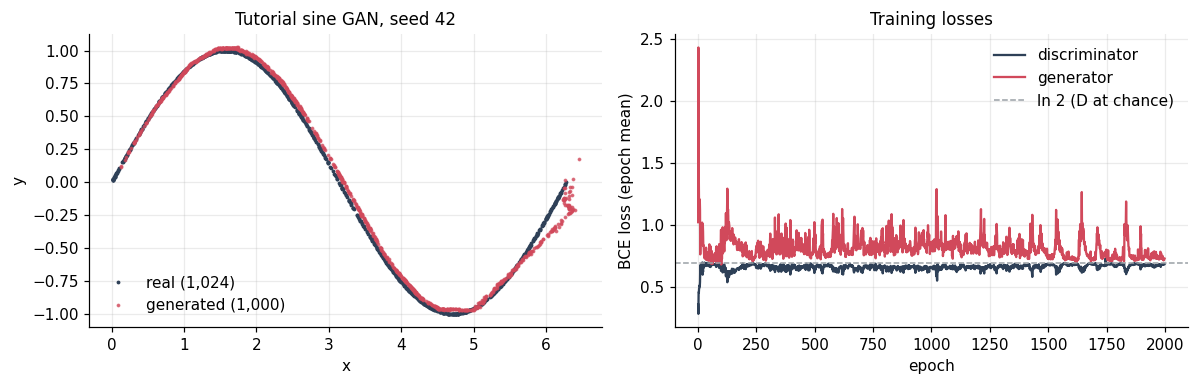

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sine_real[:, 0], sine_real[:, 1], ".", ms=3, color=HUE["real"], label="real (1,024)")
ax[0].plot(sine_fake[:, 0], sine_fake[:, 1], ".", ms=3, color=HUE["fake"], alpha=0.7, label="generated (1,000)")
ax[0].set(xlabel="x", ylabel="y", title="Tutorial sine GAN, seed 42"); ax[0].legend(loc="lower left")
ax[1].plot(sine_hist.epoch, sine_hist.loss_d, color=HUE["real"], label="discriminator")
ax[1].plot(sine_hist.epoch, sine_hist.loss_g, color=HUE["fake"], label="generator")
ax[1].axhline(math.log(2), ls="--", color=HUE["grey"], lw=1, label="ln 2 (D at chance)")
ax[1].set(xlabel="epoch", ylabel="BCE loss (epoch mean)", title="Training losses"); ax[1].legend()
fig.tight_layout(); stamp_figure(fig, "p1_sine_reproduction")

### B2. Seed sensitivity of the tutorial model

The tutorial asks whether the result depends on the seed. The identical model is retrained with two further seeds and scored with the same three measures.

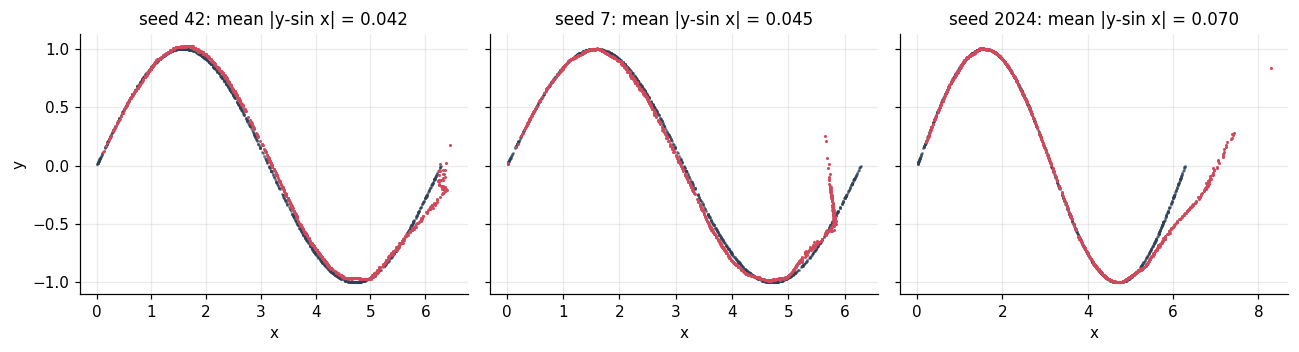

,mean_abs_resid,share_x_outside,energy_dist
seed_42,0.0424,0.033,0.0203
seed_7,0.0452,0.000,0.0275
seed_2024,0.0702,0.084,0.0223


In [9]:
seed_runs = {42: (sine_fake, sine_hist)}
for s in P1["extra_seeds"]:
    g_s, h_s = run_point_gan(sine_real, epochs=P1["epochs_sine"], seed=s)
    f_s = draw_from_point_forger(g_s, P1["n_eval"], seed=s)
    seed_runs[s] = (f_s, h_s)
    sine_scores[f"seed_{s}"] = score_sine_fit(f_s, sine_real)

fig, ax = plt.subplots(1, len(seed_runs), figsize=(4 * len(seed_runs), 3.3), sharey=True)
for a, (s, (f_s, _)) in zip(ax, seed_runs.items()):
    a.plot(sine_real[:, 0], sine_real[:, 1], ".", ms=2, color=HUE["real"], alpha=0.5)
    a.plot(f_s[:, 0], f_s[:, 1], ".", ms=2, color=HUE["fake"])
    a.set(title=f"seed {s}: mean |y-sin x| = {sine_scores[f'seed_{s}']['mean_abs_resid']:.3f}", xlabel="x")
ax[0].set_ylabel("y"); fig.tight_layout(); stamp_figure(fig, "p1_seed_sensitivity")
seed_table = pd.DataFrame(sine_scores).T.round(4); seed_table

### B3. A new 2D distribution: seven-mode Gaussian mixture

The new target is a hexagon of six Gaussians on a unit circle plus one at the origin, each with standard deviation 0.1. A mixture with well separated modes makes mode collapse visible and countable, which a single curve does not. Scores: a generated point is "high quality" if it lies within three standard deviations (0.3) of its nearest centre; a mode is "covered" if at least 1% of the 1,000 generated points are high quality for it; energy distance compares the whole generated cloud with real data.

In [10]:
HEX_CENTRES = np.vstack([[0.0, 0.0]] + [[math.cos(k * math.pi / 3), math.sin(k * math.pi / 3)] for k in range(6)])
HEX_SIGMA = 0.1

def draw_hex_mixture(n, seed):
    """n points from the seven-mode mixture: equal weights, isotropic sigma 0.1."""
    rng = np.random.default_rng(seed)
    comp = rng.integers(0, len(HEX_CENTRES), n)
    return torch.tensor(HEX_CENTRES[comp] + rng.normal(0, HEX_SIGMA, (n, 2)), dtype=torch.float32)

def score_hex_modes(gen_pts, real_pts):
    """Modes covered, share of high-quality points and energy distance for the hexagon mixture."""
    g = gen_pts.numpy()
    dist = np.linalg.norm(g[:, None, :] - HEX_CENTRES[None], axis=2)
    near, dmin = dist.argmin(1), dist.min(1)
    good = dmin < 3 * HEX_SIGMA
    per_mode = np.bincount(near[good], minlength=len(HEX_CENTRES)) / len(g)
    return {"modes_covered": int((per_mode >= 0.01).sum()), "share_high_quality": float(good.mean()),
            "energy_dist": energy_gap(gen_pts, real_pts[:len(gen_pts)])}

hex_real = draw_hex_mixture(P1["n_hex"], seed=42)

### B4. Architecture variants on both distributions

Three generator/discriminator set-ups are compared on the sine curve and the mixture with the same data, seed and budget:

* **baseline**: the tutorial networks (ReLU, generator 16-32);
* **leaky**: LeakyReLU(0.2) in both networks, which keeps a gradient for negative pre-activations;
* **deep-G**: a four-layer, 64-unit ReLU generator, which gives the generator more capacity to bend a 2D latent space into seven separated clusters.

In [11]:
VARIANTS = {"baseline": dict(g_hidden=(16, 32), act="relu"),
            "leaky": dict(g_hidden=(16, 32), act="leaky"),
            "deep-G": dict(g_hidden=(64, 64, 64, 64), act="relu")}
variant_rows, variant_pts, variant_hist = [], {}, {}
for ds_name, data, epochs, scorer in [("sine", sine_real, P1["epochs_sine"], score_sine_fit),
                                      ("hex mixture", hex_real, P1["epochs_hex"], score_hex_modes)]:
    for v_name, spec in VARIANTS.items():
        if ds_name == "sine" and v_name == "baseline":
            g_v, h_v = sine_g, sine_hist          # reuse the seed-42 reproduction, same settings
        else:
            g_v, h_v = run_point_gan(data, epochs=epochs, seed=42, **spec)
        pts = draw_from_point_forger(g_v, P1["n_eval"], seed=42)
        variant_pts[(ds_name, v_name)], variant_hist[(ds_name, v_name)] = pts, h_v
        variant_rows.append({"dataset": ds_name, "variant": v_name, **scorer(pts, data),
                             "final_loss_d": float(h_v.loss_d.tail(20).mean()),
                             "final_loss_g": float(h_v.loss_g.tail(20).mean())})
variant_table = pd.DataFrame(variant_rows)
variant_table.to_csv(OUT / "p1_variants.csv", index=False)
variant_table.round(4)

,dataset,variant,mean_abs_resid,share_x_outside,energy_dist,final_loss_d,final_loss_g,modes_covered,share_high_quality
0,sine,baseline,0.0424,0.033,0.0203,0.6785,0.7351,NaN,NaN
1,sine,leaky,0.0524,0.008,0.0056,0.6923,0.7013,NaN,NaN
2,sine,deep-G,0.7832,0.018,0.6361,0.6932,0.6931,NaN,NaN
3,hex mixture,baseline,NaN,NaN,0.0390,0.5946,0.9273,6.0,0.974
4,hex mixture,leaky,NaN,NaN,0.0178,0.6883,0.7129,7.0,0.922
5,hex mixture,deep-G,NaN,NaN,0.5693,0.6931,0.6931,1.0,0.947


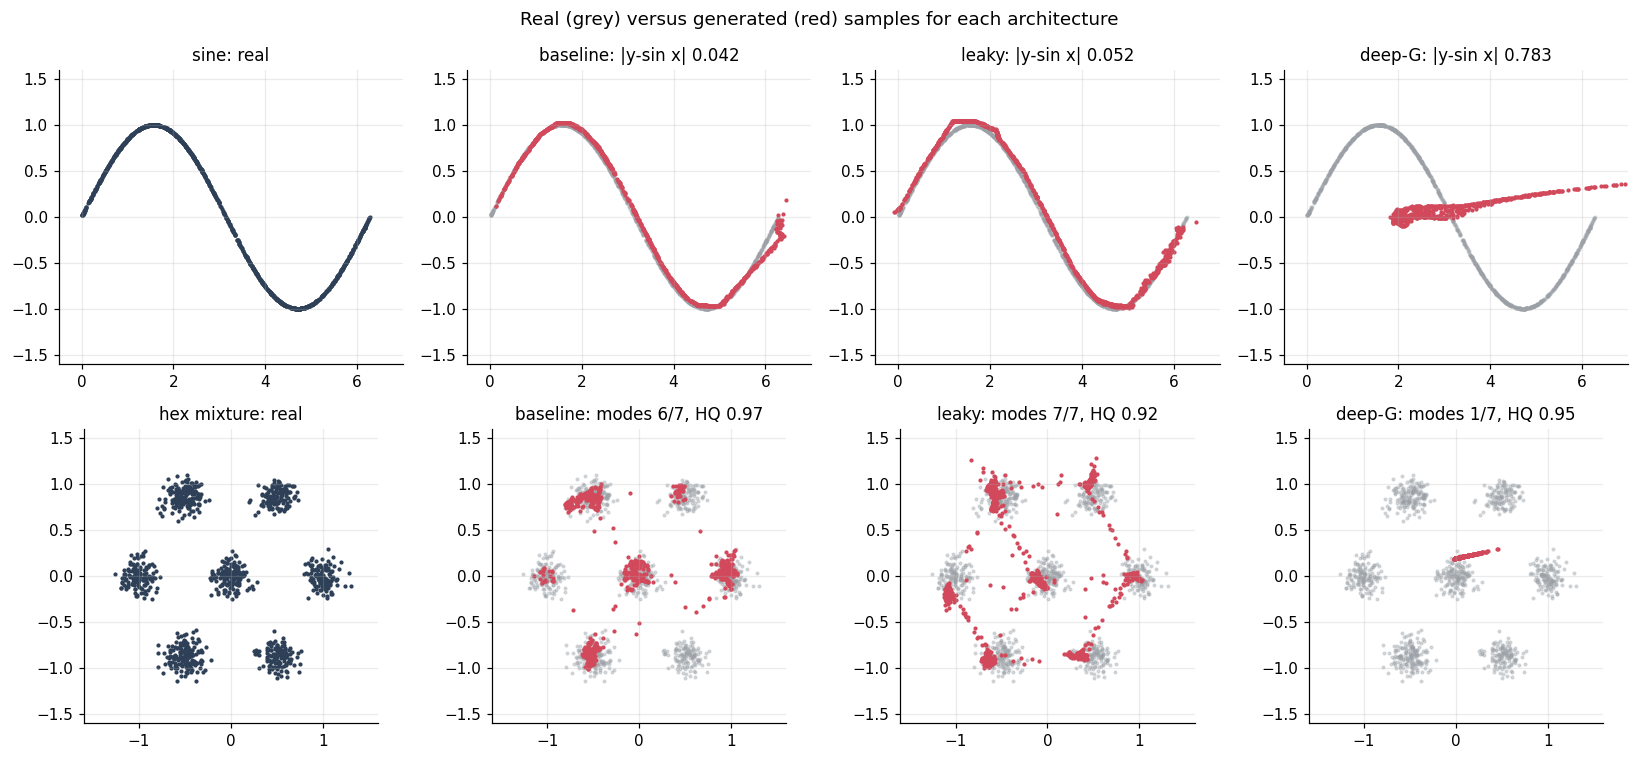

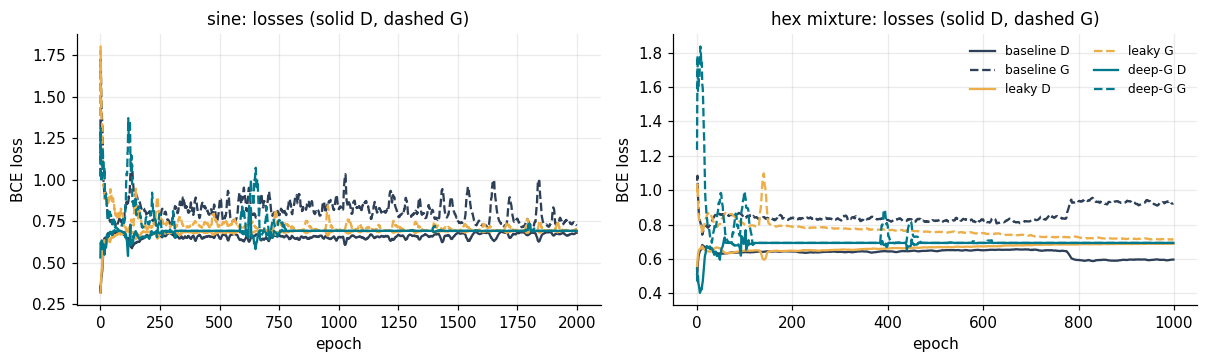

[B] 6.23 min


In [12]:
fig, ax = plt.subplots(2, 4, figsize=(15, 7))
for r, (ds_name, data) in enumerate([("sine", sine_real), ("hex mixture", hex_real)]):
    ax[r, 0].scatter(data[:1000, 0], data[:1000, 1], s=3, color=HUE["real"])
    ax[r, 0].set_title(f"{ds_name}: real")
    for c, v_name in enumerate(VARIANTS, start=1):
        pts = variant_pts[(ds_name, v_name)]
        ax[r, c].scatter(data[:1000, 0], data[:1000, 1], s=3, color=HUE["grey"], alpha=0.35)
        ax[r, c].scatter(pts[:, 0], pts[:, 1], s=3, color=HUE["fake"])
        row = variant_table[(variant_table.dataset == ds_name) & (variant_table.variant == v_name)].iloc[0]
        extra = (f"|y-sin x| {row.mean_abs_resid:.3f}" if ds_name == "sine"
                 else f"modes {int(row.modes_covered)}/7, HQ {row.share_high_quality:.2f}")
        ax[r, c].set_title(f"{v_name}: {extra}")
    lim = (-0.5, 7.0) if ds_name == "sine" else (-1.6, 1.6)
    for a in ax[r]:
        a.set_xlim(lim); a.set_ylim((-1.6, 1.6))
        if ds_name != "sine":
            a.set_aspect("equal")
fig.suptitle("Real (grey) versus generated (red) samples for each architecture"); fig.tight_layout()
stamp_figure(fig, "p1_variants_grid")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, ds_name in zip(ax, ["sine", "hex mixture"]):
    for v_name, col in zip(VARIANTS, [HUE["real"], HUE["gold"], HUE["petrol"]]):
        h = variant_hist[(ds_name, v_name)]
        a.plot(h.epoch, h.loss_d.rolling(10, min_periods=1).mean(), color=col, label=f"{v_name} D")
        a.plot(h.epoch, h.loss_g.rolling(10, min_periods=1).mean(), color=col, ls="--", label=f"{v_name} G")
    a.set(xlabel="epoch", ylabel="BCE loss", title=f"{ds_name}: losses (solid D, dashed G)")
ax[1].legend(ncol=2, fontsize=8); fig.tight_layout(); stamp_figure(fig, "p1_variant_losses")

store_json({"sine_seeds": sine_scores, "variants": variant_rows}, "p1_metrics")
station_clock("B", t0)

In [13]:
# Compact printout used when writing the interpretation below.
print(seed_table.to_string()); print(variant_table.round(3).to_string())

           mean_abs_resid  share_x_outside  energy_dist
seed_42            0.0424            0.033       0.0203
seed_7             0.0452            0.000       0.0275
seed_2024          0.0702            0.084       0.0223
       dataset   variant  mean_abs_resid  share_x_outside  energy_dist  final_loss_d  final_loss_g  modes_covered  share_high_quality
0         sine  baseline           0.042            0.033        0.020         0.678         0.735            NaN                 NaN
1         sine     leaky           0.052            0.008        0.006         0.692         0.701            NaN                 NaN
2         sine    deep-G           0.783            0.018        0.636         0.693         0.693            NaN                 NaN
3  hex mixture  baseline             NaN              NaN        0.039         0.595         0.927            6.0               0.974
4  hex mixture     leaky             NaN              NaN        0.018         0.688         0.713        

**Reading Part 1.** The reproduction learns the sine curve. With seed 42, the mean vertical error |y - sin x| of the 1,000 generated points is 0.042, and 3.3% of them fall outside [0, 2π]. Seeds 7 and 2024 give errors of 0.045 and 0.070, with 0.0% and 8.4% of points outside the range. So the tutorial model is usable, but how well it covers the ends of the curve depends on the seed.

On the mixture, the baseline puts 97.4% of its points within 0.3 of a centre but covers only 6 of the 7 modes. LeakyReLU covers all 7 and halves the energy distance (0.039 to 0.018). It pays with a lower high-quality share (0.922), because some points land between modes. On the sine curve LeakyReLU also gives the lowest energy distance (0.006 against 0.020).

The deeper generator fails on both datasets: it covers 1 of 7 modes, and its sine error is 0.783. Its final losses are 0.693 for both networks, which is ln 2, the value reached when the discriminator outputs 0.5 for everything. A loss curve sitting at the theoretical equilibrium can therefore hide a fully collapsed generator. That is why every variant here is judged on sample-based scores rather than on losses.

## Station C: Part 2.1, OCTMNIST retinal images

### C1. Loading and exploring the data

OCTMNIST (MedMNIST v2) holds 28x28 grey optical coherence tomography slices in four classes: choroidal neovascularisation (CNV), diabetic macular oedema (DME), drusen and normal. The file is read from `data/medmnist/octmnist.npz`; if it is absent it is downloaded from the MedMNIST Zenodo record (the `medmnist` package uses the same file).

In [14]:
t0 = station_clock("C")
OCT_CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]
OCT_URL = "https://zenodo.org/records/10519652/files/octmnist.npz?download=1"

def fetch_octmnist(path=DATA / "medmnist" / "octmnist.npz"):
    """Return the OCTMNIST arrays, downloading the official npz once if needed."""
    if not path.exists():
        print("downloading OCTMNIST ..."); urllib.request.urlretrieve(OCT_URL, path)
    d = np.load(path)
    return {k: d[k] for k in d.files}

oct_raw = fetch_octmnist()
oct_counts = pd.DataFrame({split: pd.Series(oct_raw[f"{split}_labels"].ravel()).value_counts().sort_index()
                           for split in ["train", "val", "test"]})
oct_counts.index = OCT_CLASSES
print({k: v.shape for k, v in oct_raw.items()})
print("class shares per split:"); print((oct_counts / oct_counts.sum()).round(4).to_string())
oct_counts

{'train_images': (97477, 28, 28), 'val_images': (10832, 28, 28), 'test_images': (1000, 28, 28), 'train_labels': (97477, 1), 'val_labels': (10832, 1), 'test_labels': (1000, 1)}
class shares per split:
         train     val  test
CNV     0.3435  0.3435  0.25
DME     0.1048  0.1048  0.25
DRUSEN  0.0795  0.0796  0.25
NORMAL  0.4722  0.4721  0.25


,train,val,test
CNV,33484,3721,250
DME,10213,1135,250
DRUSEN,7754,862,250
NORMAL,46026,5114,250


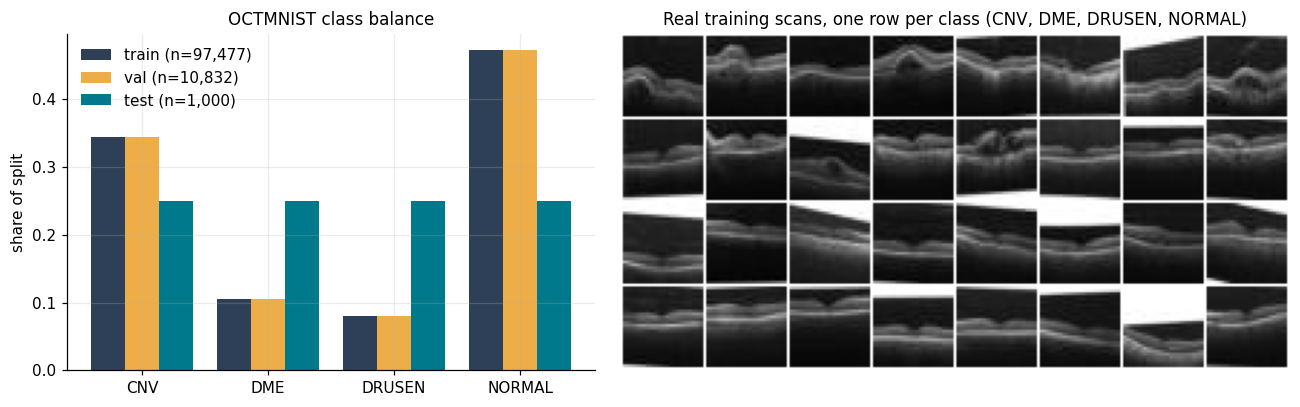

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
share = oct_counts / oct_counts.sum()
x = np.arange(4)
for k, (split, col) in enumerate(zip(share.columns, [HUE["real"], HUE["gold"], HUE["petrol"]])):
    ax[0].bar(x + (k - 1) * 0.27, share[split], 0.27, label=f"{split} (n={oct_counts[split].sum():,})", color=col)
ax[0].set_xticks(x, OCT_CLASSES); ax[0].set(ylabel="share of split", title="OCTMNIST class balance"); ax[0].legend()
rows = [oct_raw["train_images"][oct_raw["train_labels"].ravel() == c][:8] for c in range(4)]
ink_grid(ax[1], torch.tensor(np.concatenate(rows))[:, None], nrow=8, title="Real training scans, one row per class (CNV, DME, DRUSEN, NORMAL)")
fig.tight_layout(); stamp_figure(fig, "oct_explore")

### C2. DCGAN training

The DCGAN design of Radford et al. (2016) suits 28x28 scans: transposed convolutions let the generator learn local texture (the layered retinal bands and speckle) with shared filters, BatchNorm in the generator stabilises the early epochs, and strided convolutions with LeakyReLU in the discriminator avoid sparse gradients. The networks come from the shared builder `pair_conv_duelists`, which Station E reuses unchanged. The loss is non-saturating BCE with one-sided label smoothing (real target 0.9), and Adam uses lr 2e-4 and β1 = 0.5 as in the DCGAN paper.

In [16]:
def as_unit_tensor(arr):
    """uint8 array [N,28,28] -> float tensor [N,1,28,28] in [-1,1] on DEVICE."""
    return (torch.tensor(arr, dtype=torch.float32)[:, None] / 127.5 - 1).to(DEVICE)

pin_every_seed(42)
cap = CFG["oct"]["n_train_cap"]
oct_x = as_unit_tensor(oct_raw["train_images"][:cap])
oct_y = torch.tensor(oct_raw["train_labels"].ravel()[:cap], dtype=torch.long, device=DEVICE)
oct_g, oct_d = pair_conv_duelists()
print(f"generator params {sum(p.numel() for p in oct_g.parameters()):,} | discriminator params {sum(p.numel() for p in oct_d.parameters()):,}")
oct_log, oct_snaps = duel_on_images(oct_x, oct_y, oct_g, oct_d, CFG["oct"]["epochs"], seed=42)
torch.save(oct_g.state_dict(), OUT / "checkpoints" / "oct_dcgan_G.pt")
oct_log.to_csv(OUT / "oct_dcgan_log.csv", index=False)

generator params 1,911,233 | discriminator params 431,937


epoch  1/12  D 0.800  G 2.397  D(x) 0.70  D(G(z)) 0.21


epoch  2/12  D 1.058  G 1.555  D(x) 0.58  D(G(z)) 0.31


epoch  3/12  D 0.946  G 1.733  D(x) 0.62  D(G(z)) 0.28


epoch  4/12  D 0.873  G 1.925  D(x) 0.66  D(G(z)) 0.25


epoch  5/12  D 0.741  G 2.347  D(x) 0.72  D(G(z)) 0.18


... (3 outputs left out)

epoch  9/12  D 0.639  G 2.890  D(x) 0.77  D(G(z)) 0.13


epoch 10/12  D 0.651  G 2.863  D(x) 0.77  D(G(z)) 0.13


epoch 11/12  D 0.625  G 2.828  D(x) 0.77  D(G(z)) 0.13


epoch 12/12  D 0.610  G 2.926  D(x) 0.78  D(G(z)) 0.12


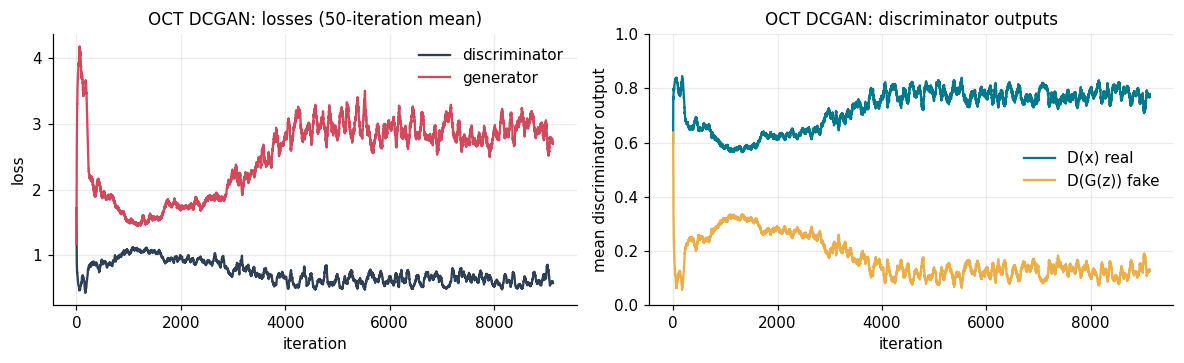

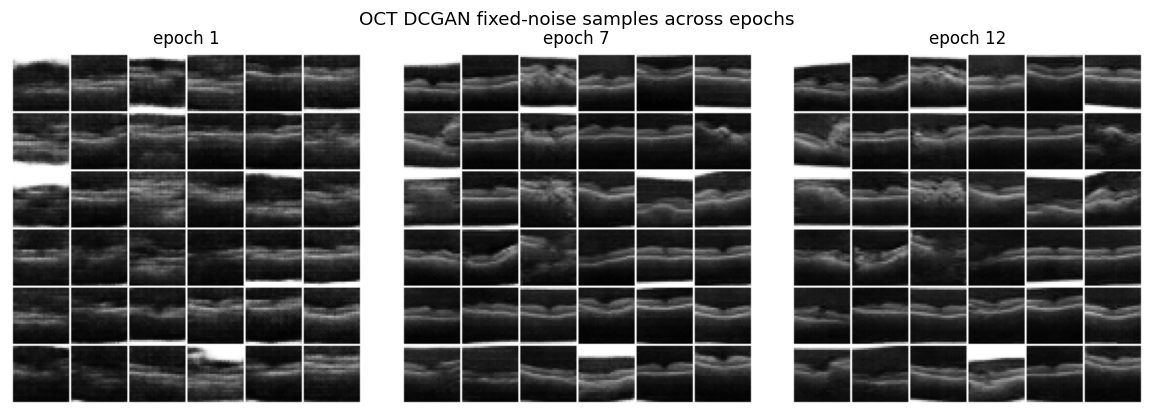

In [17]:
plot_duel_curves(oct_log, "OCT DCGAN", "oct_dcgan_curves")
plot_snap_progress(oct_snaps, "OCT DCGAN fixed-noise samples across epochs", "oct_dcgan_progress")

### C3. Real versus generated scans and quantitative scores

Three complementary measures are used, because each has a known blind spot:

* **Inception FID and KID** (Heusel et al., 2017; Bińkowski et al., 2018) on 10,000 generated scans against 10,000 held-out validation scans. The Inception network was trained on ImageNet photos, not retinal scans, so a **real-versus-real floor** (10,000 training scans against the same validation scans) is computed to show how far the score can fall.
* **Domain FID**: the same Fréchet formula on the 128-d penultimate features of a small CNN classifier trained on OCTMNIST itself, so the feature space knows what retinal pathology looks like.
* **Class mix**: the classifier's predicted labels for generated scans against its predictions for real validation scans. A GAN that drops a class shows a gap here.

In [18]:
class OctProbe(nn.Module):
    """Small CNN classifier for OCTMNIST; its 128-d penultimate layer is the feature space for domain FID."""
    def __init__(self, n_classes=4):
        super().__init__()
        self.feat = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Linear(128, 128), nn.ReLU())
        self.head = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.head(self.feat(x))

def train_oct_probe(x, y, x_val, y_val, epochs, seed=42, bs=256):
    """Train the OCT classifier (Adam, cross-entropy, lr halved every 2 epochs).

    BatchNorm running statistics make eval-mode accuracy jump between epochs, so validation
    accuracy is checked after every epoch and the best epoch's weights are kept.
    """
    pin_every_seed(seed)
    net = OctProbe().to(DEVICE); opt = torch.optim.Adam(net.parameters(), 1e-3)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5)
    gen = torch.Generator().manual_seed(seed); best = (-1.0, None, 0)
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(x), generator=gen).to(DEVICE); tot = 0.0
        for i in range(0, len(x), bs):
            idx = perm[i:i + bs]; opt.zero_grad()
            loss = F.cross_entropy(net(x[idx]), y[idx]); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        sched.step(); net.eval()
        with torch.no_grad():
            val_acc = float(np.mean([(net(x_val[j:j + 1000]).argmax(1) == y_val[j:j + 1000]).float().mean().item()
                                     for j in range(0, len(x_val), 1000)]))
        print(f"probe epoch {ep + 1}: train CE {tot / len(x):.3f} | val accuracy {val_acc:.3f}")
        if val_acc > best[0]:
            best = (val_acc, {k: v.detach().clone() for k, v in net.state_dict().items()}, ep + 1)
    net.load_state_dict(best[1])
    print(f"kept epoch {best[2]} (val accuracy {best[0]:.3f})")
    return net.eval(), best[0], best[2]

def probe_readout(net, imgs_u8, bs=1000):
    """Return (128-d features, predicted labels, max softmax) for uint8 images using the OCT probe."""
    feats, preds, conf = [], [], []
    with torch.no_grad():
        for i in range(0, len(imgs_u8), bs):
            x = (imgs_u8[i:i + bs].float() / 127.5 - 1).to(DEVICE)
            h = net.feat(x); p = F.softmax(net.head(h), 1)
            feats.append(h.cpu().double()); preds.append(p.argmax(1).cpu()); conf.append(p.max(1).values.cpu())
    return torch.cat(feats).numpy(), torch.cat(preds).numpy(), torch.cat(conf).numpy()

oct_xv = as_unit_tensor(oct_raw["val_images"]); oct_yv = torch.tensor(oct_raw["val_labels"].ravel(), dtype=torch.long, device=DEVICE)
probe, probe_val_acc, probe_epoch = train_oct_probe(oct_x, oct_y, oct_xv, oct_yv, CFG["oct"]["probe_epochs"])
test_u8 = torch.tensor(oct_raw["test_images"])[:, None]
_, test_pred, _ = probe_readout(probe, test_u8)
test_true = oct_raw["test_labels"].ravel()
probe_scores = {"val_accuracy_best_epoch": probe_val_acc, "kept_epoch": probe_epoch,
                "test_accuracy": float(accuracy_score(test_true, test_pred)),
                "test_macro_f1": float(f1_score(test_true, test_pred, average="macro"))}
print(probe_scores)
print(classification_report(test_true, test_pred, target_names=OCT_CLASSES, digits=3))

probe epoch 1: train CE 0.562 | val accuracy 0.838


probe epoch 2: train CE 0.398 | val accuracy 0.843


probe epoch 3: train CE 0.341 | val accuracy 0.853


probe epoch 4: train CE 0.324 | val accuracy 0.853


probe epoch 5: train CE 0.299 | val accuracy 0.868


probe epoch 6: train CE 0.290 | val accuracy 0.874
kept epoch 6 (val accuracy 0.874)


{'val_accuracy_best_epoch': 0.8735262263904918, 'kept_epoch': 6, 'test_accuracy': 0.703, 'test_macro_f1': 0.6577074297507033}
              precision    recall  f1-score   support

         CNV      0.655     0.948     0.775       250
         DME      0.956     0.688     0.800       250
      DRUSEN      0.978     0.180     0.304       250
      NORMAL      0.604     0.996     0.752       250

    accuracy                          0.703      1000
   macro avg      0.798     0.703     0.658      1000
weighted avg      0.798     0.703     0.658      1000



In [19]:
n_fid = CFG["oct"]["n_fid"]
rng = np.random.default_rng(42)
val_u8 = torch.tensor(oct_raw["val_images"][rng.choice(len(oct_raw["val_images"]), min(n_fid, len(oct_raw["val_images"])), replace=False)])[:, None]
trn_u8 = torch.tensor(oct_raw["train_images"][rng.choice(len(oct_raw["train_images"]), n_fid, replace=False)])[:, None]
pin_every_seed(7)
oct_fake = mint_images(oct_g, n_fid)

bank_val, bank_trn, bank_fake = inception_bank(val_u8), inception_bank(trn_u8), inception_bank(oct_fake)
fv, pv, cv = probe_readout(probe, val_u8); ft, _, _ = probe_readout(probe, trn_u8); ff, pf, cf = probe_readout(probe, oct_fake)

oct_scores = {
    "n_real_ref": len(val_u8), "n_fake": len(oct_fake),
    "fid_inception": frechet_from_bank(bank_fake, bank_val),
    "fid_inception_real_floor": frechet_from_bank(bank_trn, bank_val),
    "kid_inception": kid_from_bank(bank_fake, bank_val),
    "kid_inception_real_floor": kid_from_bank(bank_trn, bank_val),
    "fid_domain": frechet_from_bank(ff, fv),
    "fid_domain_real_floor": frechet_from_bank(ft, fv),
    "mean_probe_confidence_fake": float(cf.mean()), "mean_probe_confidence_real": float(cv.mean()),
    "probe": probe_scores,
}
mix = pd.DataFrame({"real val (probe-predicted)": np.bincount(pv, minlength=4) / len(pv),
                    "generated (probe-predicted)": np.bincount(pf, minlength=4) / len(pf),
                    "real val (true labels)": np.bincount(oct_raw["val_labels"].ravel(), minlength=4) / len(oct_raw["val_labels"])},
                   index=OCT_CLASSES)
oct_scores["class_mix"] = mix.round(4).to_dict()
store_json(oct_scores, "oct_dcgan_metrics")
print(json.dumps({k: v for k, v in oct_scores.items() if k != "class_mix"}, indent=1, default=float))
mix.round(3)

{
 "n_real_ref": 10000,
 "n_fake": 10000,
 "fid_inception": 31.674429346442803,
 "fid_inception_real_floor": 1.879341138167293,
 "kid_inception": [
  0.027444805493430202,
  0.0010528450562170206
 ],
 "kid_inception_real_floor": [
  1.600900881633116e-05,
  0.00012313024424908666
 ],
 "fid_domain": 1.5792536109927302,
 "fid_domain_real_floor": 0.017230728449729057,
 "mean_probe_confidence_fake": 0.8508389592170715,
 "mean_probe_confidence_real": 0.9198803901672363,
 "probe": {
  "val_accuracy_best_epoch": 0.8735262263904918,
  "kept_epoch": 6,
  "test_accuracy": 0.703,
  "test_macro_f1": 0.6577074297507033
 }
}


,real val (probe-predicted),generated (probe-predicted),real val (true labels)
CNV,0.323,0.246,0.344
DME,0.079,0.072,0.105
DRUSEN,0.034,0.052,0.080
NORMAL,0.564,0.630,0.472


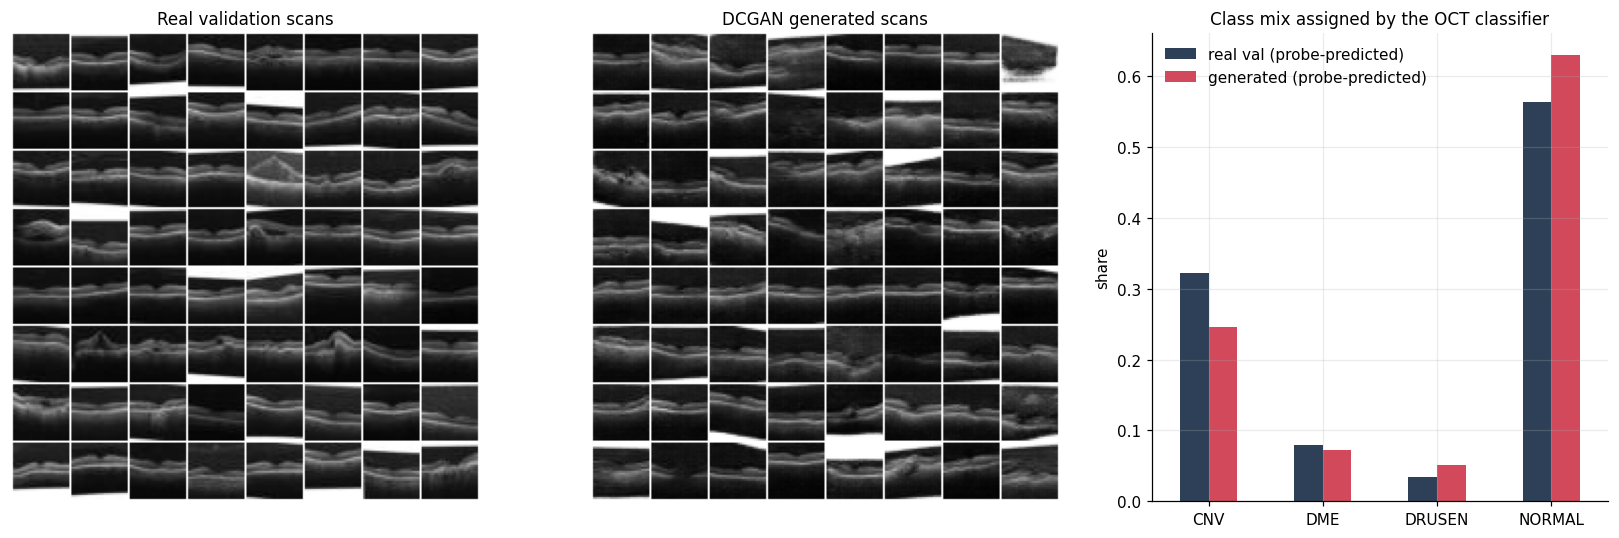

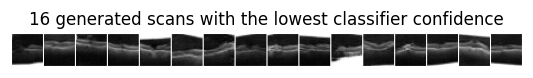

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1, 0.9]})
ink_grid(ax[0], val_u8[:64], title="Real validation scans")
ink_grid(ax[1], oct_fake[:64], title="DCGAN generated scans")
mix[["real val (probe-predicted)", "generated (probe-predicted)"]].plot.bar(ax=ax[2], color=[HUE["real"], HUE["fake"]], rot=0)
ax[2].set(ylabel="share", title="Class mix assigned by the OCT classifier")
fig.tight_layout(); stamp_figure(fig, "oct_real_vs_fake")

# Closest-looking failures: the generated scans the classifier is least sure about.
worst = np.argsort(cf)[:16]
fig, ax = plt.subplots(figsize=(6, 2.0))
ink_grid(ax, oct_fake[worst], nrow=16, title="16 generated scans with the lowest classifier confidence")
stamp_figure(fig, "oct_low_confidence_fakes")

In [21]:
print(json.dumps({k: v for k, v in oct_scores.items() if k != "class_mix"}, indent=1, default=float))
print(f"Inception FID / real floor = {oct_scores['fid_inception'] / oct_scores['fid_inception_real_floor']:.1f}x | "
      f"domain FID / real floor = {oct_scores['fid_domain'] / oct_scores['fid_domain_real_floor']:.1f}x")
dgz = oct_log.d_fake.rolling(50, min_periods=1).mean().reset_index(drop=True)
_s = min(300, len(dgz) // 4)  # skip the start-up transient before the discriminator has learned anything
print(f"rolling D(G(z)): peak {dgz.max():.3f} at iteration {int(dgz.idxmax())} (start-up); "
      f"after iteration {_s} peak {dgz.iloc[_s:].max():.3f} at iteration {int(dgz.iloc[_s:].idxmax())}")

{
 "n_real_ref": 10000,
 "n_fake": 10000,
 "fid_inception": 31.674429346442803,
 "fid_inception_real_floor": 1.879341138167293,
 "kid_inception": [
  0.027444805493430202,
  0.0010528450562170206
 ],
 "kid_inception_real_floor": [
  1.600900881633116e-05,
  0.00012313024424908666
 ],
 "fid_domain": 1.5792536109927302,
 "fid_domain_real_floor": 0.017230728449729057,
 "mean_probe_confidence_fake": 0.8508389592170715,
 "mean_probe_confidence_real": 0.9198803901672363,
 "probe": {
  "val_accuracy_best_epoch": 0.8735262263904918,
  "kept_epoch": 6,
  "test_accuracy": 0.703,
  "test_macro_f1": 0.6577074297507033
 }
}
Inception FID / real floor = 16.9x | domain FID / real floor = 91.7x
rolling D(G(z)): peak 0.637 at iteration 0 (start-up); after iteration 300 peak 0.336 at iteration 1327


**Reading the OCT results.** The generated scans reproduce the layered retinal bands, the dark vitreous above them and even the white wedge borders left by rotation in the source images. The scores show a clear but finite gap. Inception FID is 31.67 against a real-versus-real floor of 1.88, and KID is 0.0274 (std 0.0011) against 0.00002. The domain FID shows the same picture in a retina-aware feature space: 1.58 against a floor of 0.017. That is 16.9 times the floor for Inception FID and 91.7 times for domain FID. In training, leaving out the first 300 iterations, the 50-iteration mean of D(G(z)) peaks at 0.336 near iteration 1,327 before the discriminator pulls ahead again.

The classifier behind the domain features keeps its sixth epoch (validation accuracy 0.874). It reaches 0.703 on the class-balanced test set, with weak DRUSEN recall (0.18), so its class judgements are indicative rather than exact. It labels 63.0% of generated scans as NORMAL, against 56.4% of real validation scans, and 24.6% as CNV, against 32.3%. Its mean confidence is lower on fakes (0.851) than on real scans (0.920). The generator therefore leans towards the majority healthy appearance and under-produces CNV, the commonest pathology. DRUSEN gets a larger share in fakes (5.2% against 3.4%), but DRUSEN is the class the classifier judges worst. The classifier also over-predicts NORMAL on the test set (precision 0.604, recall 0.996). The least confident fakes show smeared, texture-like regions instead of distinct lesions. At 28x28, fine structures such as drusen deposits occupy a few pixels, so these images suit augmentation experiments better than any clinical use, which would need expert review.

### C4. Extension: class-conditional generation with an AC-GAN

The auxiliary-classifier GAN (Odena et al., 2017) feeds a class embedding to the generator and gives the discriminator a second head that predicts the class. The generator is therefore rewarded both for realism and for producing a scan the discriminator recognises as the requested class. The same builder is used with `n_classes=4`. Two checks show on-demand generation: the independent OCT classifier's accuracy on 1,000 scans requested per class, and a per-class domain FID against real validation scans of that class.

epoch  1/10  D 1.655  G 2.597  D(x) 0.70  D(G(z)) 0.20


epoch  2/10  D 1.691  G 1.813  D(x) 0.61  D(G(z)) 0.29


epoch  3/10  D 1.608  G 1.679  D(x) 0.60  D(G(z)) 0.30


epoch  4/10  D 1.567  G 1.696  D(x) 0.60  D(G(z)) 0.30


epoch  5/10  D 1.513  G 1.764  D(x) 0.61  D(G(z)) 0.29


epoch  6/10  D 1.445  G 1.904  D(x) 0.63  D(G(z)) 0.27


epoch  7/10  D 1.341  G 2.051  D(x) 0.66  D(G(z)) 0.24


epoch  8/10  D 1.263  G 2.233  D(x) 0.69  D(G(z)) 0.21


epoch  9/10  D 1.181  G 2.440  D(x) 0.72  D(G(z)) 0.18


epoch 10/10  D 1.144  G 2.600  D(x) 0.74  D(G(z)) 0.16


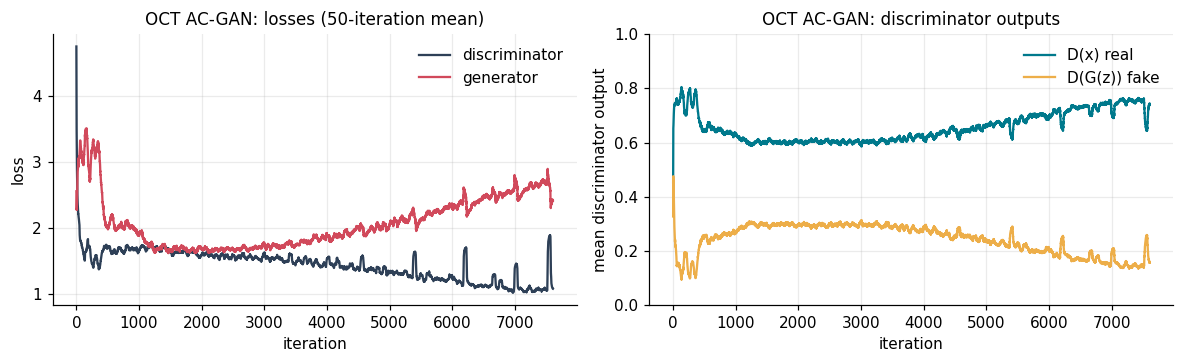

In [22]:
pin_every_seed(42)
ac_g, ac_d = pair_conv_duelists(n_classes=4)
ac_log, ac_snaps = duel_on_images(oct_x, oct_y, ac_g, ac_d, CFG["oct"]["ac_epochs"], n_classes=4, seed=42)
torch.save(ac_g.state_dict(), OUT / "checkpoints" / "oct_acgan_G.pt")
ac_log.to_csv(OUT / "oct_acgan_log.csv", index=False)
plot_duel_curves(ac_log, "OCT AC-GAN", "oct_acgan_curves")

In [23]:
k_per = CFG["oct"]["n_per_class_ac"]
pin_every_seed(11)
ask = torch.arange(4).repeat_interleave(k_per)
ac_fake = mint_images(ac_g, len(ask), labels=ask)
fa, pa, ca = probe_readout(probe, ac_fake)
val_all_u8 = torch.tensor(oct_raw["val_images"])[:, None]; val_lab = oct_raw["val_labels"].ravel()
fva, _, _ = probe_readout(probe, val_all_u8)
ac_rows = []
for c, name in enumerate(OCT_CLASSES):
    sel = ask.numpy() == c
    ac_rows.append({"class": name, "probe_recall_on_requested": float((pa[sel] == c).mean()),
                    "domain_fid_vs_real_class": frechet_from_bank(fa[sel], fva[val_lab == c]),
                    "n_real_val_class": int((val_lab == c).sum())})
ac_table = pd.DataFrame(ac_rows)
ac_scores = {"probe_accuracy_on_requested": float((pa == ask.numpy()).mean()),
             "macro_f1_on_requested": float(f1_score(ask.numpy(), pa, average="macro")),
             "per_class": ac_rows}
store_json(ac_scores, "oct_acgan_metrics"); ac_table.to_csv(OUT / "oct_acgan_per_class.csv", index=False)
print("AC-GAN: classifier accuracy on requested class =", round(ac_scores["probe_accuracy_on_requested"], 4))
ac_table.round(3)

AC-GAN: classifier accuracy on requested class = 0.3237


,class,probe_recall_on_requested,domain_fid_vs_real_class,n_real_val_class
0,CNV,0.250,31.604,3721
1,DME,0.077,18.079,1135
2,DRUSEN,0.035,14.698,862
3,NORMAL,0.933,4.077,5114


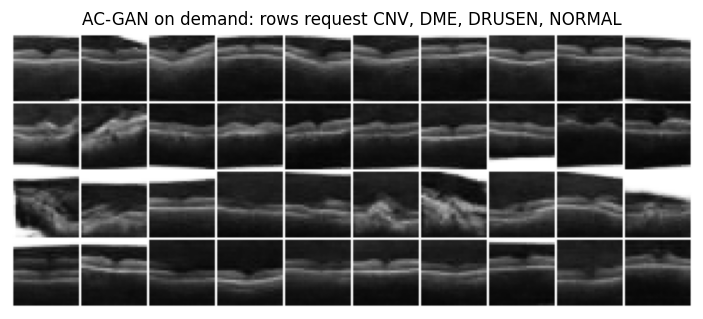

[C] 40.74 min


In [24]:
pin_every_seed(3)
grid_lab = torch.arange(4).repeat_interleave(10)
grid_imgs = mint_images(ac_g, 40, labels=grid_lab)
fig, ax = plt.subplots(figsize=(8, 3.6))
ink_grid(ax, grid_imgs, nrow=10, title="AC-GAN on demand: rows request CNV, DME, DRUSEN, NORMAL")
stamp_figure(fig, "oct_acgan_class_rows")
del oct_x, oct_y, oct_xv, oct_yv, oct_g, oct_d, ac_g, ac_d, probe  # large tensors no longer needed
release_accelerator()
station_clock("C", t0)

In [25]:
print(json.dumps(ac_scores, indent=1, default=float))

{
 "probe_accuracy_on_requested": 0.32375,
 "macro_f1_on_requested": 0.23996283186403972,
 "per_class": [
  {
   "class": "CNV",
   "probe_recall_on_requested": 0.25,
   "domain_fid_vs_real_class": 31.603635398299232,
   "n_real_val_class": 3721
  },
  {
   "class": "DME",
   "probe_recall_on_requested": 0.077,
   "domain_fid_vs_real_class": 18.078811906608873,
   "n_real_val_class": 1135
  },
  {
   "class": "DRUSEN",
   "probe_recall_on_requested": 0.035,
   "domain_fid_vs_real_class": 14.69843561245954,
   "n_real_val_class": 862
  },
  {
   "class": "NORMAL",
   "probe_recall_on_requested": 0.933,
   "domain_fid_vs_real_class": 4.077294430631109,
   "n_real_val_class": 5114
  }
 ]
}


**Reading the AC-GAN extension.** On-demand generation works only partly. The independent classifier assigns the requested class to 32.4% of conditional samples (chance is 25%; macro F1 0.240). Per-class recall is 0.933 for NORMAL, 0.250 for CNV, 0.077 for DME and 0.035 for DRUSEN, so in effect only the healthy class is under control, and some of that figure is the classifier's own lean towards NORMAL. Scans requested as DRUSEN are closer to real DRUSEN scans in the classifier's feature space (domain FID 14.70) than CNV and DME requests are to theirs (31.60 and 18.08), which suggests the low DRUSEN recall partly reflects the classifier. The row grid looks class-dependent to the eye, but the measured control is weak. Three factors combine: class differences are subtle at 28x28, the checking classifier has low DRUSEN recall itself, and the auxiliary loss on fake images lets the generator and discriminator agree on class cues that the independent classifier does not use. This result is also the least stable in the notebook: the AC-GAN training log drifts apart between reruns with the same seed after a few dozen iterations, because GPU kernels are not deterministic, and the per-class figures move with it. Improvements: longer training (the epoch-mean discriminator loss was still falling, from 1.655 to 1.144), a projection discriminator (Miyato and Koyama, 2018) in place of the auxiliary head, class-balanced sampling of real batches, and the 64x64 MedMNIST+ images, where lesions span more pixels.

## Station D: Part 2.2, synthetic network traffic from CICIDS 2017

### D1. Loading and combining the eight daily files

The CICIDS 2017 machine-learning CSVs (Sharafaldin et al., 2018) are read from `data/cicids/`. They come from the Kaggle dataset `chethuhn/network-intrusion-dataset`; download them with `kaggle datasets download -d chethuhn/network-intrusion-dataset` (needs a Kaggle API key) or manually from the dataset page, and unzip into `data/cicids/`. Column names carry stray spaces and some web-attack labels contain a broken dash character, so both are normalised on read. All days are summarised here; the core model uses Wednesday only.

In [26]:
t0 = station_clock("D")
CIC_DIR = DATA / "cicids"
FAMILY = {"BENIGN": "BENIGN", "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS",
          "DoS Slowhttptest": "DoS", "DDoS": "DDoS", "PortScan": "PortScan", "Bot": "Bot",
          "FTP-Patator": "Brute force", "SSH-Patator": "Brute force", "Web Attack - Brute Force": "Web attack",
          "Web Attack - XSS": "Web attack", "Web Attack - Sql Injection": "Web attack",
          "Infiltration": "Infiltration", "Heartbleed": "Heartbleed"}

def read_flow_day(path, nrows=None):
    """Read one CICIDS CSV with clean column names, float32 features and normalised labels."""
    df = pd.read_csv(path, nrows=nrows, encoding="latin-1", low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    lab = df.pop("Label").astype(str).str.replace(r"\s*[^\x20-\x7E]+\s*", " - ", regex=True).str.strip()
    df = df.apply(pd.to_numeric, errors="coerce").astype(np.float32)
    df["Label"] = lab.values
    return df

day_files = sorted(CIC_DIR.glob("*.csv"))
assert day_files, "No CICIDS CSVs in data/cicids/. See the download note above."
day_summary, day_frames = [], {}
for f in day_files:
    df = read_flow_day(f)
    if CFG["cic"]["smoke_frac"]:
        df = df.sample(frac=CFG["cic"]["smoke_frac"], random_state=0)
    num = df.drop(columns="Label")
    day = f.name.split(".")[0]
    day_summary.append({"file": day, "rows": len(df), "inf_cells": int(np.isinf(num.values).sum()),
                        "nan_cells": int(num.isna().values.sum()), **df.Label.value_counts().to_dict()})
    day_frames[day] = df
day_table = pd.DataFrame(day_summary).fillna(0).set_index("file")
day_table.to_csv(OUT / "cic_day_summary.csv")
print("feature columns:", num.shape[1]); print(list(num.columns))
print(f"all days: {int(day_table.rows.sum()):,} flows | {int(day_table.inf_cells.sum()):,} infinite cells | "
      f"{int(day_table.nan_cells.sum()):,} missing cells")
day_table.T

feature columns: 78
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Cou

file,Friday-WorkingHours-Afternoon-DDos,Friday-WorkingHours-Afternoon-PortScan,Friday-WorkingHours-Morning,Monday-WorkingHours,Thursday-WorkingHours-Afternoon-Infilteration,Thursday-WorkingHours-Morning-WebAttacks,Tuesday-WorkingHours,Wednesday-workingHours
rows,225745.0,286467.0,191033.0,529918.0,288602.0,170366.0,445909.0,692703.0
inf_cells,64.0,727.0,216.0,810.0,396.0,250.0,327.0,1586.0
nan_cells,4.0,15.0,28.0,64.0,18.0,20.0,201.0,1008.0
DDoS,128027.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BENIGN,97718.0,127537.0,189067.0,529918.0,288566.0,168186.0,432074.0,440031.0
PortScan,0.0,158930.0,0.0,0.0,0.0,0.0,0.0,0.0
Bot,0.0,0.0,1966.0,0.0,0.0,0.0,0.0,0.0
Infiltration,0.0,0.0,0.0,0.0,36.0,0.0,0.0,0.0
Web Attack - Brute Force,0.0,0.0,0.0,0.0,0.0,1507.0,0.0,0.0
Web Attack - XSS,0.0,0.0,0.0,0.0,0.0,652.0,0.0,0.0


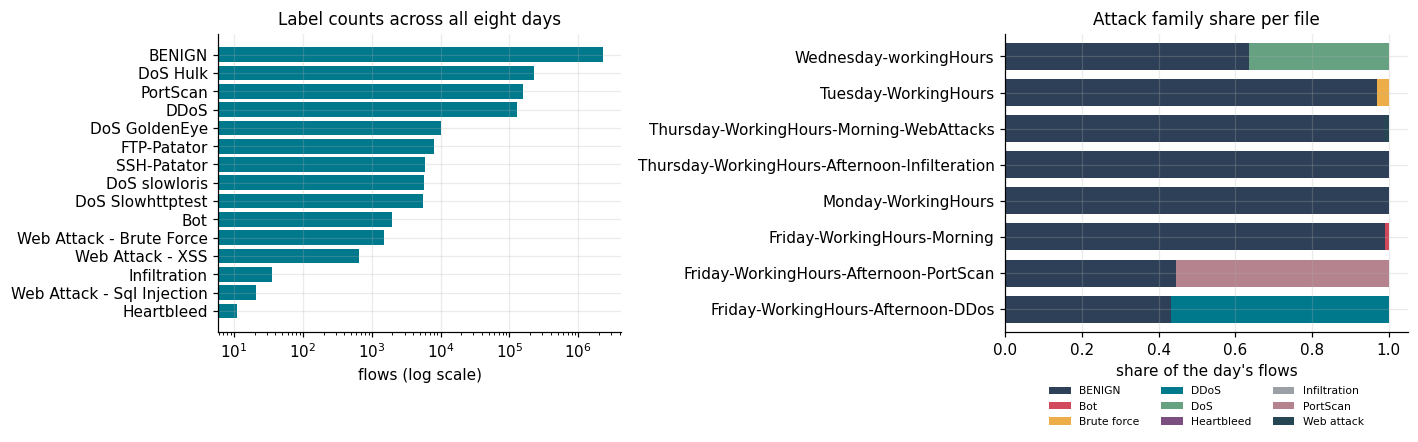

In [27]:
lab_cols = [c for c in day_table.columns if c not in ("rows", "inf_cells", "nan_cells")]
lab_tot = day_table[lab_cols].sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(lab_tot.index[::-1], lab_tot.values[::-1], color=HUE["petrol"]); ax[0].set_xscale("log")
ax[0].set(xlabel="flows (log scale)", title="Label counts across all eight days")
by_day = day_table[lab_cols].T.groupby(lambda l: FAMILY.get(l, l)).sum()
(by_day / by_day.sum()).T.plot.barh(stacked=True, ax=ax[1], width=0.75,
                                    color=[HUE[k] for k in ("real", "fake", "gold", "petrol", "sage", "plum", "grey")] + ["#B5838D", "#264653"])
ax[1].set(xlabel="share of the day's flows", ylabel="", title="Attack family share per file")
ax[1].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout(); stamp_figure(fig, "cic_explore")

### D2. Cleaning the Wednesday file

Core data: Wednesday BENIGN flows and the four DoS tools (Hulk, GoldenEye, slowloris, Slowhttptest). Heartbleed is also in the Wednesday file but has only a handful of rows, so it is left out of the core model and its count is reported. Steps, in order: infinite values become missing, rows with missing values are dropped, exact duplicate rows are dropped (CICIDS has many repeated flows, and duplicates spanning the split would leak into the test set), then constant and duplicated columns are removed. Features get a signed log transform, sign(x)·log(1+|x|), because flow durations and byte counts span many orders of magnitude, and are then scaled to [-1, 1] with minimum and maximum taken from the training split only.

In [28]:
CORE_LABELS = ["BENIGN", "DoS Hulk", "DoS GoldenEye", "DoS slowloris", "DoS Slowhttptest"]

def tidy_flow_table(df, keep_labels):
    """Filter labels, replace inf with NaN, drop NaN rows and exact duplicates; returns (frame, audit dict)."""
    audit = {"rows_in": int(len(df))}
    df = df[df.Label.isin(keep_labels)].replace([np.inf, -np.inf], np.nan)
    audit["rows_kept_labels"] = int(len(df))
    df = df.dropna(); audit["rows_after_nan_drop"] = int(len(df))
    df = df.drop_duplicates(); audit["rows_after_dedup"] = int(len(df))
    return df.reset_index(drop=True), audit

def useful_columns(df):
    """Feature columns that are neither constant nor exact copies of an earlier column."""
    feats = [c for c in df.columns if c != "Label" and df[c].nunique() > 1]
    seen, keep = {}, []
    for c in feats:
        key = pd.util.hash_pandas_object(df[c], index=False).sum()
        if key not in seen:
            seen[key] = c; keep.append(c)
    return keep

def squash_signed(x):
    """Signed log transform for heavy-tailed, sometimes negative, flow features."""
    return np.sign(x) * np.log1p(np.abs(x))

class RangeScaler:
    """Min-max scaling to [-1, 1] fitted on training rows only (columns with zero range map to 0)."""
    def fit(self, x):
        self.lo, self.hi = x.min(0), x.max(0); return self
    def transform(self, x):
        span = np.where(self.hi > self.lo, self.hi - self.lo, 1.0)
        return (2 * (x - self.lo) / span - 1).astype(np.float32)
    def inverse(self, x):
        return (x + 1) / 2 * (self.hi - self.lo) + self.lo

wed_key = [k for k in day_frames if k.lower().startswith("wednesday")][0]
wed = day_frames[wed_key]
heartbleed_rows = int((wed.Label == "Heartbleed").sum())
wed_core, wed_audit = tidy_flow_table(wed, CORE_LABELS)
FEATS = useful_columns(wed_core)
wed_audit.update({"heartbleed_rows_excluded": heartbleed_rows, "n_features_raw": int(wed.shape[1] - 1),
                  "n_features_kept": len(FEATS), "dropped_columns": [c for c in wed.columns if c not in FEATS + ["Label"]]})
print(json.dumps(wed_audit, indent=1)); print(wed_core.Label.value_counts())
print(f"incomplete rows dropped {wed_audit['rows_kept_labels'] - wed_audit['rows_after_nan_drop']:,} | "
      f"exact duplicates dropped {wed_audit['rows_after_nan_drop'] - wed_audit['rows_after_dedup']:,} | "
      f"columns removed {len(wed_audit['dropped_columns'])}")
_complete = wed[wed.Label.isin(CORE_LABELS)].replace([np.inf, -np.inf], np.nan).dropna()
dup_share = _complete.duplicated().groupby(_complete.Label).agg(["sum", "size", "mean"])
dup_share.columns = ["duplicates", "complete_rows", "share"]
print("exact-duplicate share per label (complete rows):"); print(dup_share.round(4).to_string())
del _complete

{
 "rows_in": 692703,
 "rows_kept_labels": 692692,
 "rows_after_nan_drop": 691395,
 "rows_after_dedup": 610442,
 "heartbleed_rows_excluded": 11,
 "n_features_raw": 78,
 "n_features_kept": 61,
 "dropped_columns": [
  "Bwd PSH Flags",
  "Fwd URG Flags",
  "Bwd URG Flags",
  "SYN Flag Count",
  "CWE Flag Count",
  "Avg Fwd Segment Size",
  "Avg Bwd Segment Size",
  "Fwd Header Length.1",
  "Fwd Avg Bytes/Bulk",
  "Fwd Avg Packets/Bulk",
  "Fwd Avg Bulk Rate",
  "Bwd Avg Bytes/Bulk",
  "Bwd Avg Packets/Bulk",
  "Bwd Avg Bulk Rate",
  "Subflow Fwd Packets",
  "Subflow Fwd Bytes",
  "Subflow Bwd Packets"
 ]
}
Label
BENIGN              416712
DoS Hulk            172846
DoS GoldenEye        10282
DoS slowloris         5374
DoS Slowhttptest      5228
Name: count, dtype: int64
incomplete rows dropped 1,297 | exact duplicates dropped 80,953 | columns removed 17


exact-duplicate share per label (complete rows):
                  duplicates  complete_rows   share
Label                                              
BENIGN                 22971         439683  0.0522
DoS GoldenEye             11          10293  0.0011
DoS Hulk               57278         230124  0.2489
DoS Slowhttptest         271           5499  0.0493
DoS slowloris            422           5796  0.0728


In [29]:
CORE_NAMES = CORE_LABELS
y_all = wed_core.Label.map({l: i for i, l in enumerate(CORE_NAMES)}).values
X_all = squash_signed(wed_core[FEATS].values.astype(np.float64))
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=42)
scaler = RangeScaler().fit(X_tr_raw)
X_tr, X_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)
split_counts = pd.DataFrame({"train": np.bincount(y_tr, minlength=5), "test": np.bincount(y_te, minlength=5)}, index=CORE_NAMES)
wed_audit["split_counts"] = split_counts.to_dict()
split_counts

,train,test
BENIGN,333369,83343
DoS Hulk,138277,34569
DoS GoldenEye,8226,2056
DoS slowloris,4299,1075
DoS Slowhttptest,4182,1046


### D3. A conditional WGAN-GP for flow vectors

Flow records are tabular, heavy-tailed and multi-class, so the network is a pair of MLPs rather than convolutions. Two choices follow from the data. First, the plain BCE GAN loss tends to collapse onto the dominant benign and Hulk modes, so the model uses the Wasserstein loss with gradient penalty (Gulrajani et al., 2017), whose critic gives a useful gradient even when real and generated distributions barely overlap. Second, both networks receive the one-hot class (Mirza and Osindero, 2014), and each batch draws classes uniformly, so the three small DoS tools get as many updates as benign traffic and labelled synthetic data can be generated on demand.

In [30]:
class TabForger(nn.Module):
    """Conditional MLP generator for scaled flow vectors: [z, one-hot class] -> features in [-1, 1]."""
    def __init__(self, z_dim, n_classes, n_out, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(z_dim + n_classes, hidden), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, n_out), nn.Tanh())
    def forward(self, z, y1h):
        return self.net(torch.cat([z, y1h], 1))

class TabCritic(nn.Module):
    """Conditional MLP critic (no BatchNorm, which would break the per-sample gradient penalty)."""
    def __init__(self, n_in, n_classes, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in + n_classes, hidden), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, hidden), nn.LeakyReLU(0.2), nn.Linear(hidden, 1))
    def forward(self, x, y1h):
        return self.net(torch.cat([x, y1h], 1)).squeeze(1)

def gp_penalty_term(critic, real, fake, y1h):
    """WGAN-GP penalty: (||grad critic(x_hat)|| - 1)^2 on random interpolates between real and fake."""
    eps = torch.rand(real.shape[0], 1)
    x_hat = (eps * real + (1 - eps) * fake).requires_grad_(True)
    grad = torch.autograd.grad(critic(x_hat, y1h).sum(), x_hat, create_graph=True)[0]
    return ((grad.norm(2, dim=1) - 1) ** 2).mean()

def class_balanced_draw(y, n_classes, bs, gen):
    """Indices for one batch with classes drawn uniformly, then rows drawn uniformly within each class."""
    order = np.argsort(y, kind="stable"); counts = np.bincount(y, minlength=n_classes); starts = np.r_[0, np.cumsum(counts)[:-1]]
    yb = torch.randint(0, n_classes, (bs,), generator=gen).numpy()
    off = (torch.rand(bs, generator=gen).numpy() * counts[yb]).astype(int)
    return order[starts[yb] + off], yb

def duel_wgan_tab(X, y, n_classes, iters, seed=42):
    """Train a conditional WGAN-GP on scaled features X with integer labels y (CPU). Returns (G, log)."""
    c = CFG["cic"]; pin_every_seed(seed); gen = torch.Generator().manual_seed(seed)
    G = TabForger(c["z_dim"], n_classes, X.shape[1], c["hidden"]); D = TabCritic(X.shape[1], n_classes, c["hidden"])
    opt_g = torch.optim.Adam(G.parameters(), lr=c["lr"], betas=c["betas"])
    opt_d = torch.optim.Adam(D.parameters(), lr=c["lr"], betas=c["betas"])
    Xt = torch.tensor(X); eye = torch.eye(n_classes); rows = []
    for it in range(iters):
        for _ in range(c["n_critic"]):
            idx, yb = class_balanced_draw(y, n_classes, c["batch"], gen)
            real, y1h = Xt[idx], eye[yb]
            fake = G(torch.randn(len(idx), c["z_dim"], generator=gen), y1h).detach()
            w_gap = D(real, y1h).mean() - D(fake, y1h).mean()
            gp = gp_penalty_term(D, real, fake, y1h)
            opt_d.zero_grad(); (-w_gap + c["gp"] * gp).backward(); opt_d.step()
        yb = torch.randint(0, n_classes, (c["batch"],), generator=gen)
        for p in D.parameters():
            p.requires_grad_(False)
        loss_g = -D(G(torch.randn(c["batch"], c["z_dim"], generator=gen), eye[yb]), eye[yb]).mean()
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()
        for p in D.parameters():
            p.requires_grad_(True)
        if it % 10 == 0:
            rows.append((it, float(-w_gap + c["gp"] * gp), float(w_gap), float(gp), float(loss_g)))
        if it % max(1, iters // 8) == 0:
            print(f"iter {it:5d}  critic {rows[-1][1]:.3f}  W-estimate {rows[-1][2]:.3f}  GP {rows[-1][3]:.3f}")
    return G.eval(), pd.DataFrame(rows, columns=["iter", "critic_loss", "w_estimate", "grad_penalty", "gen_loss"])

def mint_flows(G, counts, seed):
    """Generate synthetic scaled flows with the given number of rows per class; returns (X, y)."""
    gen = torch.Generator().manual_seed(seed); eye = torch.eye(len(counts))
    y = np.repeat(np.arange(len(counts)), counts)
    with torch.no_grad():
        X = G(torch.randn(len(y), CFG["cic"]["z_dim"], generator=gen), eye[y]).numpy()
    return X, y

torch.set_num_threads(os.cpu_count() or 4)
cic_G, cic_log = duel_wgan_tab(X_tr, y_tr, 5, CFG["cic"]["iters"])
torch.save(cic_G.state_dict(), OUT / "checkpoints" / "cic_wgangp_G.pt"); cic_log.to_csv(OUT / "cic_wgangp_log.csv", index=False)

iter     0  critic 8.980  W-estimate 0.021  GP 0.900


iter  1000  critic -1.341  W-estimate 1.477  GP 0.014


iter  2000  critic -0.874  W-estimate 0.957  GP 0.008


iter  3000  critic -0.739  W-estimate 0.812  GP 0.007


iter  4000  critic -0.644  W-estimate 0.728  GP 0.008


iter  5000  critic -0.699  W-estimate 0.795  GP 0.010


iter  6000  critic -0.549  W-estimate 0.626  GP 0.008


iter  7000  critic -0.411  W-estimate 0.480  GP 0.007


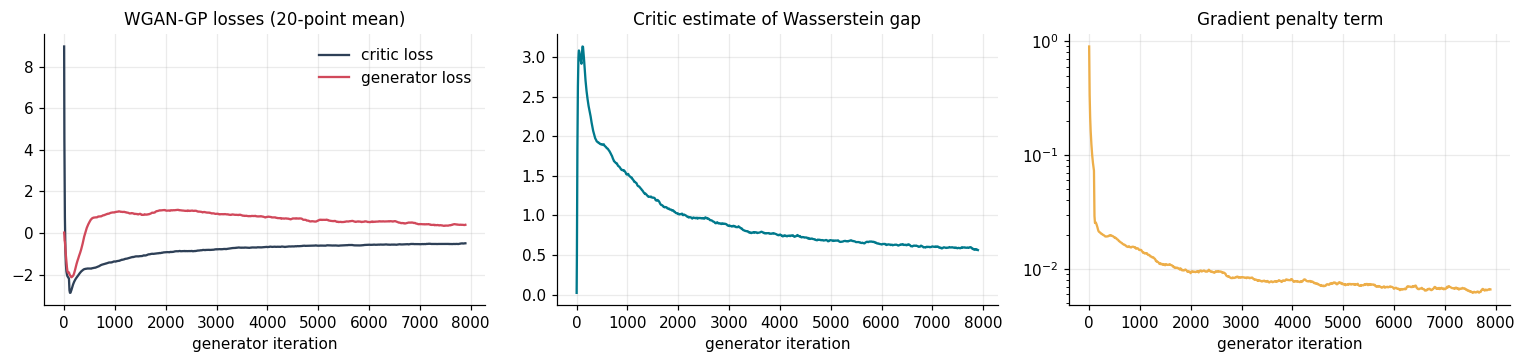

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
r = cic_log.rolling(20, min_periods=1).mean()
ax[0].plot(r.iter, r.critic_loss, color=HUE["real"], label="critic loss"); ax[0].plot(r.iter, r.gen_loss, color=HUE["fake"], label="generator loss")
ax[0].set(xlabel="generator iteration", title="WGAN-GP losses (20-point mean)"); ax[0].legend()
ax[1].plot(r.iter, r.w_estimate, color=HUE["petrol"]); ax[1].set(xlabel="generator iteration", title="Critic estimate of Wasserstein gap")
ax[2].plot(r.iter, r.grad_penalty, color=HUE["gold"]); ax[2].set(xlabel="generator iteration", title="Gradient penalty term"); ax[2].set_yscale("log")
fig.tight_layout(); stamp_figure(fig, "cic_wgangp_curves")

### D4. How close are synthetic flows to real ones?

The evaluation set holds real test flows and an equal number of synthetic flows with the same class mix. Five views are used: PCA (fitted on real training data) and t-SNE projections; per-feature Kolmogorov-Smirnov statistics and Wasserstein-1 distances on the scaled features; the gap between real and synthetic correlation matrices; a random-forest detector that tries to tell real from synthetic (AUC 0.5 means indistinguishable); and train-on-synthetic, test-on-real (TSTR) against train-on-real, test-on-real (TRTR) with the same number of rows per class (Esteban et al., 2017).

In [32]:
def matched_eval_sets(X_real, y_real, G, n, seed, n_classes):
    """Subsample n real rows and generate synthetic rows with exactly the same class counts."""
    rng = np.random.default_rng(seed); pick = rng.choice(len(X_real), min(n, len(X_real)), replace=False)
    Xr, yr = X_real[pick], y_real[pick]
    Xs, ys = mint_flows(G, np.bincount(yr, minlength=n_classes), seed)
    return Xr, yr, Xs, ys

def ks_wass_table(Xr, Xs, names):
    """Per-feature two-sample KS statistic and Wasserstein-1 distance (scaled feature space)."""
    rows = [{"feature": n, "ks": stats.ks_2samp(Xr[:, j], Xs[:, j]).statistic,
             "wasserstein": stats.wasserstein_distance(Xr[:, j], Xs[:, j])} for j, n in enumerate(names)]
    return pd.DataFrame(rows).sort_values("ks", ascending=False).reset_index(drop=True)

def corr_gap(Xr, Xs):
    """Real and synthetic correlation matrices and their mean absolute difference (NaN-safe)."""
    cr, cs = np.nan_to_num(np.corrcoef(Xr, rowvar=False)), np.nan_to_num(np.corrcoef(Xs, rowvar=False))
    return cr, cs, float(np.abs(cr - cs)[np.triu_indices_from(cr, 1)].mean())

def separability_auc(Xr, Xs, seed=42):
    """5-fold ROC AUC of a random forest asked to tell real (1) from synthetic (0) rows."""
    X = np.vstack([Xr, Xs]); y = np.r_[np.ones(len(Xr)), np.zeros(len(Xs))]
    rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed, min_samples_leaf=2)
    return float(cross_val_score(rf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=seed), scoring="roc_auc").mean())

def tstr_vs_trtr(X_tr_real, y_tr_real, G, X_test, y_test, per_class, names, seed=42):
    """Train identical random forests on synthetic vs real rows (same per-class counts), test both on real."""
    rng = np.random.default_rng(seed); k = len(names)
    take = [rng.choice(np.where(y_tr_real == c)[0], min(per_class, (y_tr_real == c).sum()), replace=False) for c in range(k)]
    idx = np.concatenate(take); counts = np.array([len(t) for t in take])
    Xs, ys = mint_flows(G, counts, seed + 1)
    out = {}
    for tag, (Xa, ya) in {"TRTR": (X_tr_real[idx], y_tr_real[idx]), "TSTR": (Xs, ys)}.items():
        rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed).fit(Xa, ya)
        pred = rf.predict(X_test)
        out[tag] = {"macro_f1": float(f1_score(y_test, pred, average="macro")),
                    "per_class_recall": dict(zip(names, recall_score(y_test, pred, average=None, labels=range(k)).round(6).tolist()))}
    out["rows_per_class"] = dict(zip(names, counts.tolist()))
    return out

c = CFG["cic"]
Xr, yr, Xs, ys = matched_eval_sets(X_te, y_te, cic_G, c["eval_n"], seed=42, n_classes=5)
ks_tab = ks_wass_table(Xr, Xs, FEATS); ks_tab.to_csv(OUT / "cic_ks_wasserstein.csv", index=False)
cr, cs, cgap = corr_gap(Xr, Xs)
# Xr and Xs hold the same number of rows per class (matched_eval_sets), so the full sets are used:
# the detector cannot separate on class composition. (Slicing a class-sorted Xs would break the match.)
assert (np.bincount(yr, minlength=5) == np.bincount(ys, minlength=5)).all()
auc = separability_auc(Xr, Xs)
# What drives detectability? (a) drop the near-discrete features (at most 10 distinct values in the real
# training rows, i.e. the flag counts and similar); (b) keep all features but snap every synthetic value to the
# nearest value seen in the real training rows, which removes the "near miss" signal of the tanh output.
n_distinct = np.array([len(np.unique(X_tr[:, j])) for j in range(X_tr.shape[1])])
DISCRETE = [f for f, n in zip(FEATS, n_distinct) if n <= 10]
keep_j = [j for j, f in enumerate(FEATS) if f not in DISCRETE]
auc_no_discrete = separability_auc(Xr[:, keep_j], Xs[:, keep_j])
def snap_to_real_grid(Xsyn, Xref):
    """Replace each synthetic value by the nearest value of that feature present in Xref."""
    out = np.empty_like(Xsyn)
    for j in range(Xsyn.shape[1]):
        u = np.unique(Xref[:, j]); pos = np.clip(np.searchsorted(u, Xsyn[:, j]), 1, len(u) - 1)
        lo, hi = u[pos - 1], u[pos]
        out[:, j] = np.where(np.abs(Xsyn[:, j] - lo) <= np.abs(hi - Xsyn[:, j]), lo, hi)
    return out
auc_snapped = separability_auc(Xr, snap_to_real_grid(Xs, X_tr))
rf_imp = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42, min_samples_leaf=2).fit(
    np.vstack([Xr, Xs]), np.r_[np.ones(len(Xr)), np.zeros(len(Xs))])
auc_importance = pd.Series(rf_imp.feature_importances_, index=FEATS).sort_values(ascending=False)
print(f"detector AUC on {len(Xr):,} real vs {len(Xs):,} synthetic rows (same class counts): {auc:.4f}")
print(f"  without the {len(DISCRETE)} near-discrete features {DISCRETE}: {auc_no_discrete:.4f}")
print(f"  with synthetic values snapped to the real value grid: {auc_snapped:.4f}")
print("  top-10 detector feature importances:"); print(auc_importance.head(10).round(4).to_string())
tstr = tstr_vs_trtr(X_tr, y_tr, cic_G, X_te, y_te, c["tstr_per_class"], CORE_NAMES)
per_class_ks = {CORE_NAMES[k]: float(ks_wass_table(Xr[yr == k], Xs[ys == k], FEATS).ks.mean()) for k in range(5)}
cic_scores = {"audit": wed_audit, "ks_mean": float(ks_tab.ks.mean()), "ks_median": float(ks_tab.ks.median()),
              "share_features_ks_below_0.1": float((ks_tab.ks < 0.1).mean()),
              "wasserstein_mean": float(ks_tab.wasserstein.mean()), "ks_mean_per_class": per_class_ks,
              "corr_mean_abs_diff": cgap, "real_vs_synth_auc": auc, "auc_n_each": int(len(Xr)),
              "auc_without_discrete": auc_no_discrete, "discrete_features": DISCRETE,
              "auc_snapped_to_real_grid": auc_snapped,
              "auc_top_importances": auc_importance.head(10).round(4).to_dict(), "tstr_trtr": tstr}
store_json(cic_scores, "cic_wgangp_metrics")
print(json.dumps({k: v for k, v in cic_scores.items() if k != "audit"}, indent=1, default=float))
ks_tab.head(10).round(3)

detector AUC on 20,000 real vs 20,000 synthetic rows (same class counts): 1.0000
  without the 7 near-discrete features ['Fwd PSH Flags', 'FIN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'ECE Flag Count']: 1.0000
  with synthetic values snapped to the real value grid: 1.0000
  top-10 detector feature importances:
Fwd Packet Length Min     0.0993
Bwd Packet Length Min     0.0686
Fwd Packet Length Std     0.0632
Min Packet Length         0.0574
Down/Up Ratio             0.0542
Fwd IAT Std               0.0516
ECE Flag Count            0.0514
Bwd IAT Std               0.0492
RST Flag Count            0.0407
Init_Win_bytes_forward    0.0359


{
 "ks_mean": 0.32473360655737704,
 "ks_median": 0.29615,
 "share_features_ks_below_0.1": 0.11475409836065574,
 "wasserstein_mean": 0.037692415646695294,
 "ks_mean_per_class": {
  "BENIGN": 0.3593215975516302,
  "DoS Hulk": 0.4235131444868786,
  "DoS GoldenEye": 0.37275089964014396,
  "DoS slowloris": 0.401311475409836,
  "DoS Slowhttptest": 0.48176122221268564
 },
 "corr_mean_abs_diff": 0.0502204961678216,
 "real_vs_synth_auc": 1.0,
 "auc_n_each": 20000,
 "auc_without_discrete": 1.0,
 "discrete_features": [
  "Fwd PSH Flags",
  "FIN Flag Count",
  "RST Flag Count",
  "PSH Flag Count",
  "ACK Flag Count",
  "URG Flag Count",
  "ECE Flag Count"
 ],
 "auc_snapped_to_real_grid": 0.9999995875,
 "auc_top_importances": {
  "Fwd Packet Length Min": 0.0993,
  "Bwd Packet Length Min": 0.0686,
  "Fwd Packet Length Std": 0.0632,
  "Min Packet Length": 0.0574,
  "Down/Up Ratio": 0.0542,
  "Fwd IAT Std": 0.0516,
  "ECE Flag Count": 0.0514,
  "Bwd IAT Std": 0.0492,
  "RST Flag Count": 0.0407,
  "Ini

,feature,ks,wasserstein
0,URG Flag Count,0.855,0.025
1,RST Flag Count,0.811,0.002
2,ECE Flag Count,0.736,0.003
3,PSH Flag Count,0.718,0.039
4,Fwd PSH Flags,0.662,0.040
5,Bwd Packet Length Min,0.594,0.031
6,Idle Std,0.577,0.019
7,FIN Flag Count,0.571,0.046
8,Min Packet Length,0.560,0.045
9,Fwd Packet Length Min,0.553,0.041


PCA: first two components explain 0.7120 of the variance


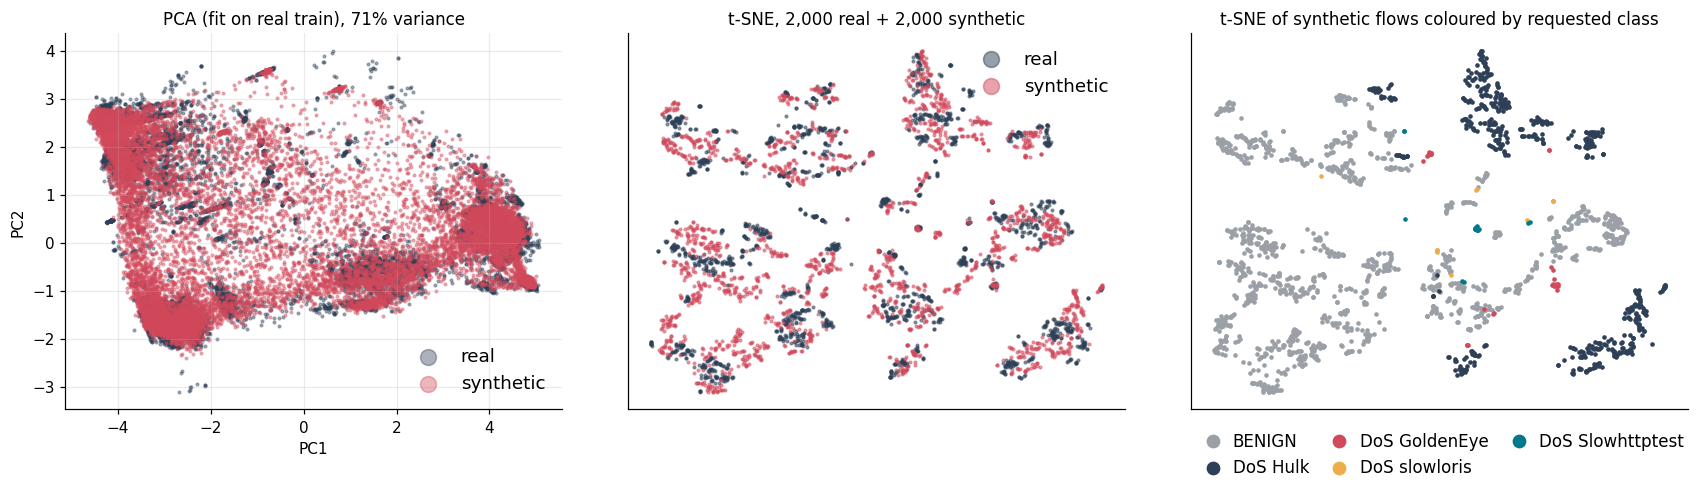

In [33]:
pca = PCA(2, random_state=42).fit(X_tr[np.random.default_rng(0).choice(len(X_tr), min(50000, len(X_tr)), replace=False)])
pr, ps = pca.transform(Xr), pca.transform(Xs)
m = c["tsne_n"]; rng = np.random.default_rng(1)
ir, is_ = rng.choice(len(Xr), min(m, len(Xr)), replace=False), rng.choice(len(Xs), min(m, len(Xs)), replace=False)
emb = TSNE(2, perplexity=30, init="pca", random_state=42).fit_transform(np.vstack([Xr[ir], Xs[is_]]))
er, es = emb[:len(ir)], emb[len(ir):]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].scatter(pr[:, 0], pr[:, 1], s=3, alpha=0.4, color=HUE["real"], label="real")
ax[0].scatter(ps[:, 0], ps[:, 1], s=3, alpha=0.4, color=HUE["fake"], label="synthetic")
ax[0].set(title=f"PCA (fit on real train), {pca.explained_variance_ratio_.sum():.0%} variance", xlabel="PC1", ylabel="PC2")
ax[0].legend(markerscale=6, fontsize=12, framealpha=0.9)
print(f"PCA: first two components explain {pca.explained_variance_ratio_.sum():.4f} of the variance")
ax[1].scatter(er[:, 0], er[:, 1], s=3, alpha=0.5, color=HUE["real"], label="real")
ax[1].scatter(es[:, 0], es[:, 1], s=3, alpha=0.5, color=HUE["fake"], label="synthetic")
ax[1].set(title=f"t-SNE, {len(ir):,} real + {len(is_):,} synthetic"); ax[1].legend(markerscale=6, fontsize=12, framealpha=0.9)
cols = [HUE[k] for k in ("grey", "real", "fake", "gold", "petrol")]
for k in range(5):
    ax[2].scatter(es[ys[is_] == k, 0], es[ys[is_] == k, 1], s=4, color=cols[k], label=CORE_NAMES[k])
ax[2].set(title="t-SNE of synthetic flows coloured by requested class")
ax[2].legend(markerscale=4, fontsize=11, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False, columnspacing=0.8, handletextpad=0.2)
for a in ax[1:]:
    a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); stamp_figure(fig, "cic_pca_tsne")

worst three KS: [['URG Flag Count', 0.8547, 0.0252], ['RST Flag Count', 0.8108, 0.0024], ['ECE Flag Count', 0.7357, 0.0028]]
best three KS: [['Flow IAT Mean', 0.0622, 0.0402], ['Packet Length Mean', 0.086, 0.033], ['Average Packet Size', 0.086, 0.0307]]


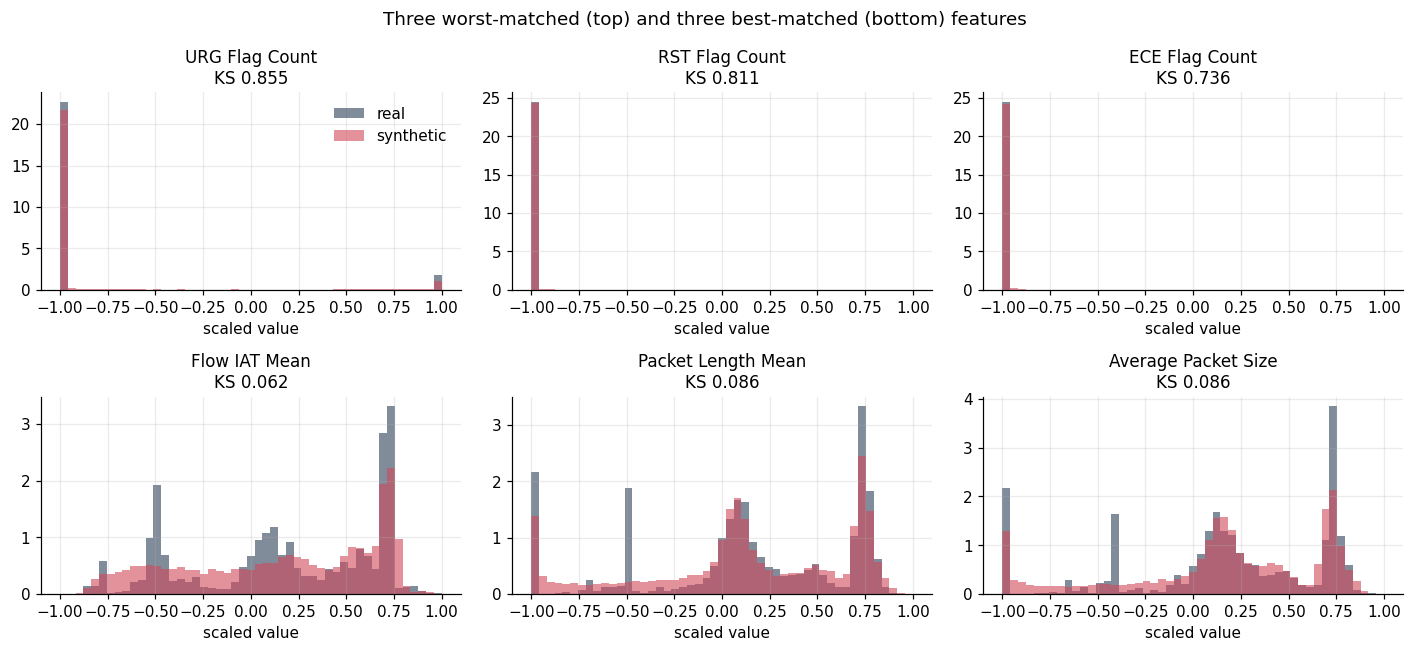

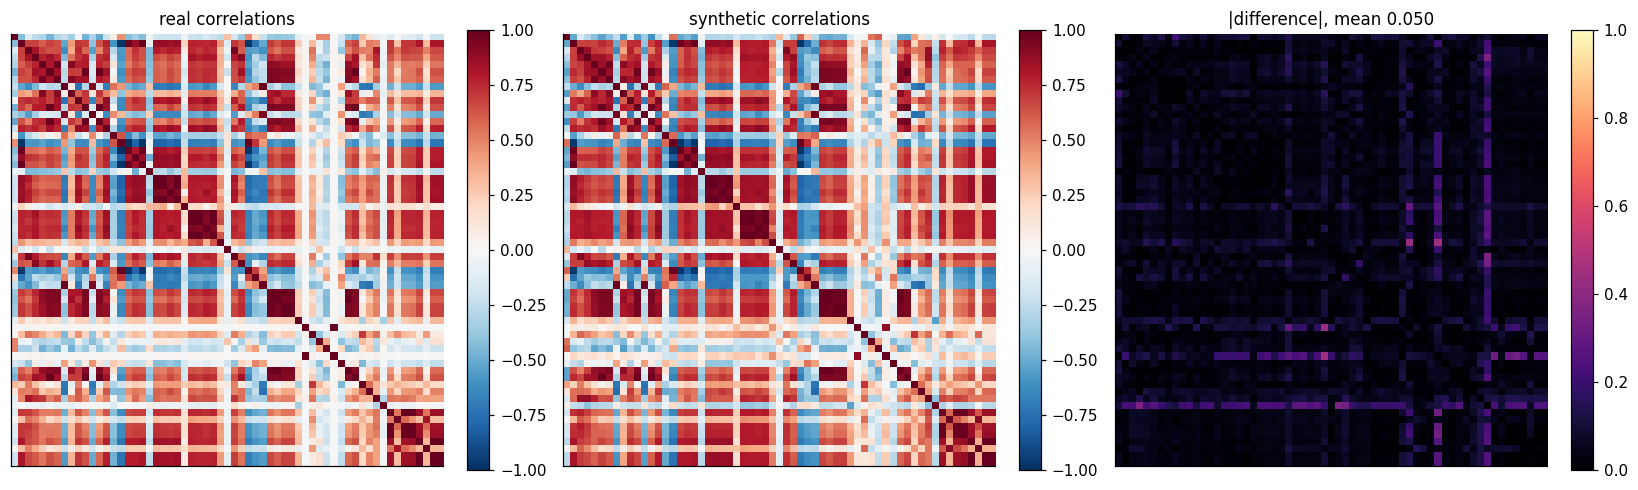

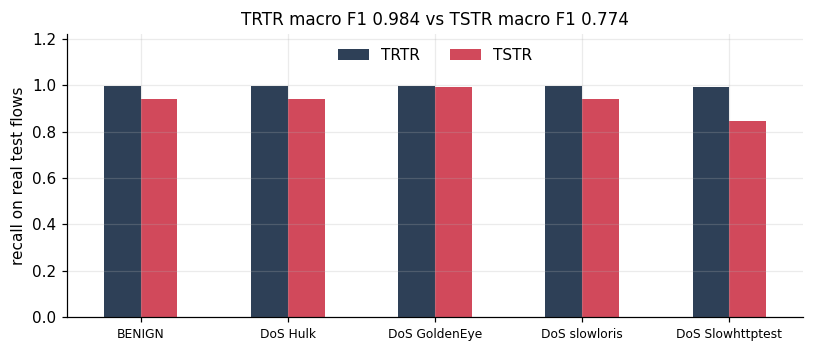

In [34]:
show = ks_tab.feature.head(3).tolist() + ks_tab.feature.tail(3).tolist()[::-1]  # worst three, then best three (best first)
print("worst three KS:", ks_tab.head(3).round(4).values.tolist()); print("best three KS:", ks_tab.tail(3)[::-1].round(4).values.tolist())
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, f in zip(ax.ravel(), show):
    j = FEATS.index(f)
    bins = np.linspace(-1, 1, 50)
    a.hist(Xr[:, j], bins=bins, alpha=0.6, density=True, color=HUE["real"], label="real")
    a.hist(Xs[:, j], bins=bins, alpha=0.6, density=True, color=HUE["fake"], label="synthetic")
    a.set(title=f"{f}\nKS {ks_tab.set_index('feature').ks[f]:.3f}", xlabel="scaled value")
ax[0, 0].legend(); fig.suptitle("Three worst-matched (top) and three best-matched (bottom) features"); fig.tight_layout()
stamp_figure(fig, "cic_feature_marginals")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, mat, t in zip(ax, [cr, cs, np.abs(cr - cs)], ["real correlations", "synthetic correlations", f"|difference|, mean {cgap:.3f}"]):
    im = a.imshow(mat, cmap="RdBu_r" if "diff" not in t else "magma", vmin=-1 if "diff" not in t else 0, vmax=1)
    a.set(title=t, xticks=[], yticks=[]); a.grid(False); plt.colorbar(im, ax=a, fraction=0.046)
fig.tight_layout(); stamp_figure(fig, "cic_correlation_gap")

tt = pd.DataFrame({k: v["per_class_recall"] for k, v in tstr.items() if k in ("TRTR", "TSTR")})
fig, ax = plt.subplots(figsize=(7.5, 3.3))
tt.plot.bar(ax=ax, color=[HUE["real"], HUE["fake"]], rot=0)
ax.set(ylabel="recall on real test flows", ylim=(0, 1.22),
       title=f"TRTR macro F1 {tstr['TRTR']['macro_f1']:.3f} vs TSTR macro F1 {tstr['TSTR']['macro_f1']:.3f}")
ax.legend(loc="upper center", ncol=2, framealpha=0.95)
ax.tick_params(axis="x", labelsize=8); fig.tight_layout(); stamp_figure(fig, "cic_tstr_trtr")

In [35]:
print(json.dumps({k: v for k, v in cic_scores.items() if k != "audit"}, indent=1, default=float)); print(ks_tab.head(8).round(3).to_string())
_b = tstr["TSTR"]["per_class_recall"]["BENIGN"]
print(f"TSTR BENIGN recall {_b:.4f}: {1 - _b:.4f} of the {int(np.bincount(y_te)[0]):,} real benign test flows are flagged as attacks")
print(f"features with KS below 0.1: {int((ks_tab.ks < 0.1).sum())} of {len(ks_tab)}")

{
 "ks_mean": 0.32473360655737704,
 "ks_median": 0.29615,
 "share_features_ks_below_0.1": 0.11475409836065574,
 "wasserstein_mean": 0.037692415646695294,
 "ks_mean_per_class": {
  "BENIGN": 0.3593215975516302,
  "DoS Hulk": 0.4235131444868786,
  "DoS GoldenEye": 0.37275089964014396,
  "DoS slowloris": 0.401311475409836,
  "DoS Slowhttptest": 0.48176122221268564
 },
 "corr_mean_abs_diff": 0.0502204961678216,
 "real_vs_synth_auc": 1.0,
 "auc_n_each": 20000,
 "auc_without_discrete": 1.0,
 "discrete_features": [
  "Fwd PSH Flags",
  "FIN Flag Count",
  "RST Flag Count",
  "PSH Flag Count",
  "ACK Flag Count",
  "URG Flag Count",
  "ECE Flag Count"
 ],
 "auc_snapped_to_real_grid": 0.9999995875,
 "auc_top_importances": {
  "Fwd Packet Length Min": 0.0993,
  "Bwd Packet Length Min": 0.0686,
  "Fwd Packet Length Std": 0.0632,
  "Min Packet Length": 0.0574,
  "Down/Up Ratio": 0.0542,
  "Fwd IAT Std": 0.0516,
  "ECE Flag Count": 0.0514,
  "Bwd IAT Std": 0.0492,
  "RST Flag Count": 0.0407,
  "Ini

**Reading the Wednesday results.** Cleaning keeps 610,442 of 692,703 flows after removing 1,297 rows with missing or infinite values and 80,953 exact duplicates, and keeps 61 of 78 features. The synthetic data keeps the joint structure far better than the individual marginals. The mean absolute difference between the real and synthetic correlation matrices is only 0.050, and the t-SNE clusters of real and synthetic flows overlap. However, the mean per-feature KS statistic is 0.325 and only 11.5% of features are below 0.1. The worst features are flag counts (URG 0.855, RST 0.811, ECE 0.736, PSH 0.718). These are discrete or nearly binary, while a tanh generator outputs continuous values. A random forest separates real from synthetic flows perfectly: AUC 1.000 on 20,000 real against 20,000 synthetic flows with the same class counts. The flags are not what drives this. Without the seven near-discrete flag features the AUC is still 1.000, and snapping every synthetic value to the nearest value seen in real training flows leaves it at 1.000. The forest's most important features are minimum and spread features (Fwd Packet Length Min, Bwd Packet Length Min, Fwd Packet Length Std), which are among the worst-matched continuous features (KS 0.553, 0.594 and 0.480). Detectability therefore comes from many imperfect features at once. The best-matched features are Flow IAT Mean (KS 0.062) and two packet-length statistics (0.086).

The utility test is more encouraging. A forest trained only on synthetic flows reaches recall between 0.939 and 0.992 for BENIGN, Hulk, GoldenEye and slowloris, and 0.846 for Slowhttptest, on real test traffic. Its macro F1 is 0.774 against 0.984 when trained on real flows. The F1 gap is larger than the recall gap because 5.7% of the 83,343 real benign test flows (1 minus the TSTR BENIGN recall of 0.942515) are labelled as attacks, which lowers precision for the small DoS classes. Handling discrete columns explicitly, as in CTGAN's mode-specific normalisation and conditional sampling (Xu et al., 2019), is the obvious next step.

### D5. Extension: all eight days grouped into attack families

The extension pools all days, maps the fifteen labels into nine families (benign, DoS, DDoS, port scan, bot, brute force, web attack, infiltration, Heartbleed) and keeps at most a fixed number of flows per family so that benign traffic does not swamp the rare classes. The same cleaning, feature list, transform and conditional WGAN-GP are reused. The question is how well the model generalises across very different attack behaviours and very different amounts of data.

In [36]:
pool = []
for day, df in day_frames.items():
    d, _ = tidy_flow_table(df, list(FAMILY)); d["Family"] = d.Label.map(FAMILY); pool.append(d)
pool = pd.concat(pool, ignore_index=True)
FAM_NAMES = [f for f in ["BENIGN", "DoS", "DDoS", "PortScan", "Bot", "Brute force", "Web attack", "Infiltration", "Heartbleed"] if f in set(pool.Family)]
fam_available = pool.Family.value_counts().reindex(FAM_NAMES)
cap_n = CFG["cic"]["family_cap"]
pool = pool.sample(frac=1.0, random_state=42).groupby("Family").head(cap_n)  # at most cap_n random rows per family
del day_frames  # free memory: only the capped pool is needed from here
yf_all = pool.Family.map({f: i for i, f in enumerate(FAM_NAMES)}).values
Xf_all = squash_signed(pool[FEATS].values.astype(np.float64))
strat = yf_all if np.bincount(yf_all).min() >= 2 else None
Xf_tr_raw, Xf_te_raw, yf_tr, yf_te = train_test_split(Xf_all, yf_all, test_size=0.2, stratify=strat, random_state=42)
fscaler = RangeScaler().fit(Xf_tr_raw)
Xf_tr, Xf_te = fscaler.transform(Xf_tr_raw), fscaler.transform(Xf_te_raw)
fam_counts = pd.DataFrame({"available_after_cleaning": fam_available, "used": pd.Series(np.bincount(yf_all, minlength=len(FAM_NAMES)), index=FAM_NAMES),
                           "train": np.bincount(yf_tr, minlength=len(FAM_NAMES)), "test": np.bincount(yf_te, minlength=len(FAM_NAMES))}, index=FAM_NAMES)
fam_counts

,available_after_cleaning,used,train,test
BENIGN,2146709,12000,9600,2400
DoS,193730,12000,9600,2400
DDoS,128014,12000,9600,2400
PortScan,90694,12000,9600,2400
Bot,1948,1948,1558,390
Brute force,9150,9150,7320,1830
Web attack,2143,2143,1714,429
Infiltration,36,36,29,7
Heartbleed,11,11,9,2


In [37]:
fam_G, fam_log = duel_wgan_tab(Xf_tr, yf_tr, len(FAM_NAMES), CFG["cic"]["iters_ext"], seed=42)
torch.save(fam_G.state_dict(), OUT / "checkpoints" / "cic_family_wgangp_G.pt")
fam_tstr = tstr_vs_trtr(Xf_tr, yf_tr, fam_G, Xf_te, yf_te, CFG["cic"]["tstr_per_class"], FAM_NAMES)
Xfr, yfr, Xfs, yfs = matched_eval_sets(Xf_te, yf_te, fam_G, len(Xf_te), seed=5, n_classes=len(FAM_NAMES))
fam_rows = []
for k, fam in enumerate(FAM_NAMES):
    sel_r, sel_s = yfr == k, yfs == k
    ks_k = ks_wass_table(Xfr[sel_r], Xfs[sel_s], FEATS).ks.mean() if sel_r.sum() >= 2 else np.nan
    fam_rows.append({"family": fam, "train_rows": int(fam_counts.loc[fam, "train"]), "test_rows": int(sel_r.sum()),
                     "ks_mean": float(ks_k), "TRTR_recall": fam_tstr["TRTR"]["per_class_recall"][fam],
                     "TSTR_recall": fam_tstr["TSTR"]["per_class_recall"][fam]})
fam_table = pd.DataFrame(fam_rows); fam_table.to_csv(OUT / "cic_family_extension.csv", index=False)
store_json({"counts": fam_counts.to_dict(), "per_family": fam_rows,
            "TRTR_macro_f1": fam_tstr["TRTR"]["macro_f1"], "TSTR_macro_f1": fam_tstr["TSTR"]["macro_f1"]}, "cic_family_metrics")
print("TRTR macro F1", round(fam_tstr["TRTR"]["macro_f1"], 4), "| TSTR macro F1", round(fam_tstr["TSTR"]["macro_f1"], 4))
fam_table.round(3)

iter     0  critic 9.080  W-estimate 0.006  GP 0.909


iter   750  critic -1.272  W-estimate 1.418  GP 0.015


iter  1500  critic -1.042  W-estimate 1.154  GP 0.011


iter  2250  critic -0.914  W-estimate 0.993  GP 0.008


iter  3000  critic -0.718  W-estimate 0.801  GP 0.008


iter  3750  critic -0.734  W-estimate 0.806  GP 0.007


iter  4500  critic -0.635  W-estimate 0.699  GP 0.006


iter  5250  critic -0.548  W-estimate 0.632  GP 0.008


TRTR macro F1 0.9792 | TSTR macro F1 0.8988


,family,train_rows,test_rows,ks_mean,TRTR_recall,TSTR_recall
0,BENIGN,9600,2400,0.357,0.990,0.805
1,DoS,9600,2400,0.404,0.996,0.894
2,DDoS,9600,2400,0.386,1.000,1.000
3,PortScan,9600,2400,0.583,0.997,0.981
4,Bot,1558,390,0.435,1.000,0.992
5,Brute force,7320,1830,0.417,1.000,0.973
6,Web attack,1714,429,0.698,0.986,0.944
7,Infiltration,29,7,0.515,0.857,0.714
8,Heartbleed,9,2,0.820,1.000,1.000


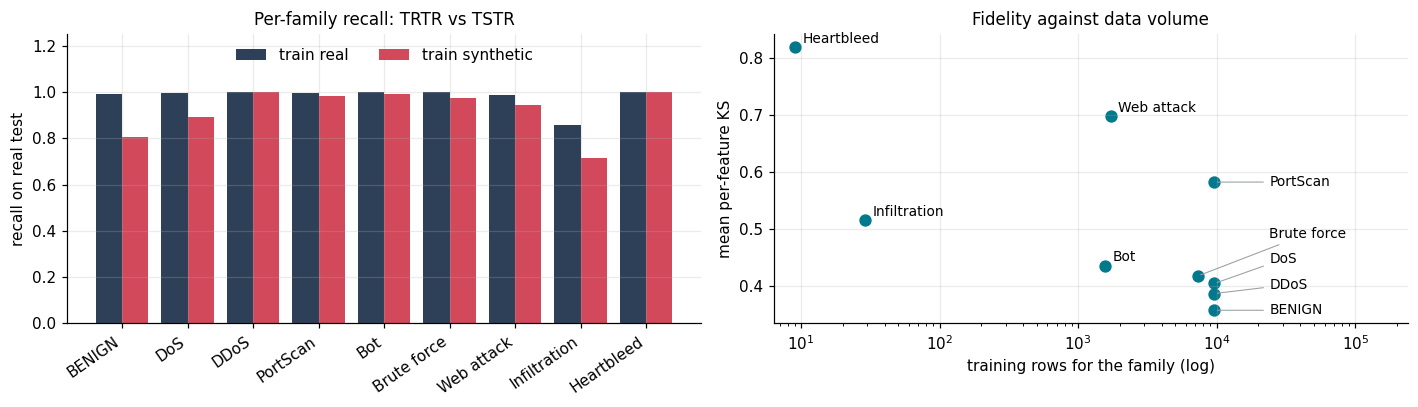

[D] 42.25 min


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
xx = np.arange(len(FAM_NAMES))
ax[0].bar(xx - 0.2, fam_table.TRTR_recall, 0.4, color=HUE["real"], label="train real")
ax[0].bar(xx + 0.2, fam_table.TSTR_recall, 0.4, color=HUE["fake"], label="train synthetic")
ax[0].set_xticks(xx, FAM_NAMES, rotation=35, ha="right"); ax[0].set(ylabel="recall on real test", ylim=(0, 1.25), title="Per-family recall: TRTR vs TSTR")
ax[0].legend(loc="upper center", ncol=2, framealpha=0.95)
ax[1].scatter(fam_table.train_rows, fam_table.ks_mean, s=50, color=HUE["petrol"])
crowd = fam_table[fam_table.train_rows >= 5000].sort_values("ks_mean")  # families at the cap sit on top of each other
lab_y, prev = {}, -np.inf
for fam_, ks_ in zip(crowd.family, crowd.ks_mean):
    prev = max(ks_, prev + 0.045); lab_y[fam_] = prev  # labels at least 0.045 apart on the KS axis
for _, rw in fam_table.iterrows():
    if rw.family in lab_y:
        ax[1].annotate(rw.family, (rw.train_rows, rw.ks_mean), xytext=(fam_table.train_rows.max() * 2.5, lab_y[rw.family]), fontsize=9,
                       ha="left", va="center", arrowprops=dict(arrowstyle="-", color=HUE["grey"], lw=0.7))
    else:
        ax[1].annotate(rw.family, (rw.train_rows, rw.ks_mean), fontsize=9, xytext=(5, 3), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlim(right=fam_table.train_rows.max() * 25)
ax[1].set(xlabel="training rows for the family (log)", ylabel="mean per-feature KS", title="Fidelity against data volume")
fig.tight_layout(); stamp_figure(fig, "cic_family_extension")
station_clock("D", t0)

In [39]:
print(fam_table.round(3).to_string()); print(fam_tstr["TRTR"]["macro_f1"], fam_tstr["TSTR"]["macro_f1"])

         family  train_rows  test_rows  ks_mean  TRTR_recall  TSTR_recall
0        BENIGN        9600       2400    0.357        0.990        0.805
1           DoS        9600       2400    0.404        0.996        0.894
2          DDoS        9600       2400    0.386        1.000        1.000
3      PortScan        9600       2400    0.583        0.997        0.981
4           Bot        1558        390    0.435        1.000        0.992
5   Brute force        7320       1830    0.417        1.000        0.973
6    Web attack        1714        429    0.698        0.986        0.944
7  Infiltration          29          7    0.515        0.857        0.714
8    Heartbleed           9          2    0.820        1.000        1.000
0.9792478344561988 0.898833621581373


**Reading the all-days extension.** Pooling all eight days into nine families, the synthetic-trained forest reaches macro F1 0.899 against 0.979 for real data. Families with distinctive traffic signatures transfer well: DDoS (TSTR recall 0.9996), Bot (0.992), PortScan (0.981), brute force (0.973) and web attacks (0.944). Benign traffic is the weakest large class (0.805), because it is the most varied. The rare families show the limit of generalisation. Infiltration has 29 training flows and 7 test flows (TSTR recall 0.714). Heartbleed has 9 and 2, so its recall of 1.0 rests on two flows and says nothing. Its KS of 0.820 compares two real with two synthetic flows and cannot be interpreted either; among families with enough data, web attacks match worst (0.698). Small classes also inflate KS in general, so per-family KS rankings should be read with the row counts in mind. The generator reproduces attack types it has seen thousands of times, but it cannot invent convincing variants from a few dozen examples. This matters because rare attacks are exactly where synthetic data would be most useful.

## Station E: Part 2.3, QuickDraw birthday cake sketches

### E1. Downloading and exploring the category

The QuickDraw numpy bitmaps (Ha and Eck, 2018; Google Creative Lab dataset) are 28x28 rasterised doodles with white strokes on black. They are downloaded once into `data/quickdraw/` and loaded with `allow_pickle=False`. Sketches are shown as dark ink on white for readability; the model works on the raw values. Disjoint random subsets are used for training and for the FID reference set.

birthday cake: 144,982 sketches | train 60,000 | reference 10,000


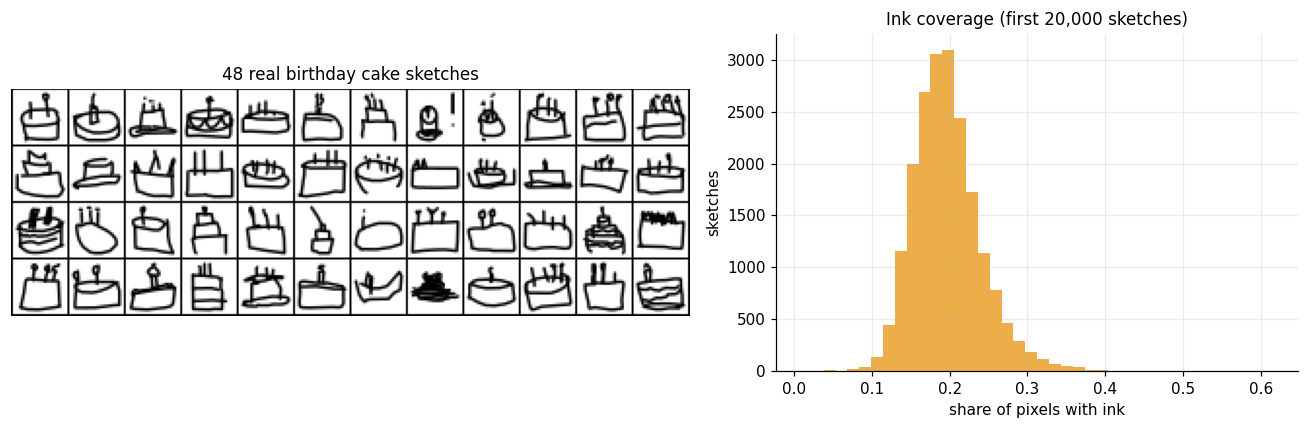

In [40]:
t0 = station_clock("E")
QD_URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{}.npy"

def fetch_sketch_category(name):
    """Return all bitmaps of one QuickDraw category as uint8 [N,28,28], downloading once if needed."""
    path = DATA / "quickdraw" / f"{name}.npy"
    if not path.exists():
        print("downloading", name); urllib.request.urlretrieve(QD_URL.format(name.replace(" ", "%20")), path)
    return np.load(path, allow_pickle=False).reshape(-1, 28, 28)

def sketch_complexity(arr):
    """Per-image ink fraction (pixels > 127) and edge-pixel count (ink pixels with a 4-neighbour that is not ink)."""
    ink = arr > 127
    pad = np.pad(ink, ((0, 0), (1, 1), (1, 1)))
    interior = pad[:, :-2, 1:-1] & pad[:, 2:, 1:-1] & pad[:, 1:-1, :-2] & pad[:, 1:-1, 2:]
    return ink.mean((1, 2)), (ink & ~interior).sum((1, 2))

def split_sketches(arr, n_train, n_ref, seed=42):
    """Disjoint random training and reference subsets from one category."""
    idx = np.random.default_rng(seed).permutation(len(arr))
    return arr[idx[:n_train]], arr[idx[n_train:n_train + n_ref]]

cake_all = fetch_sketch_category("birthday cake")
cake_tr, cake_ref = split_sketches(cake_all, CFG["qd"]["n_train"], CFG["qd"]["n_ref"])
ink_frac, edges = sketch_complexity(cake_all[:20000])
print(f"birthday cake: {len(cake_all):,} sketches | train {len(cake_tr):,} | reference {len(cake_ref):,}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.3, 1]})
ink_grid(ax[0], torch.tensor(cake_tr[:48])[:, None], nrow=12, title="48 real birthday cake sketches", invert=True)
ax[1].hist(ink_frac, bins=40, color=HUE["gold"]); ax[1].set(xlabel="share of pixels with ink", ylabel="sketches", title="Ink coverage (first 20,000 sketches)")
fig.tight_layout(); stamp_figure(fig, "qd_explore")

### E2. DCGAN training with FID tracked across epochs

The same DCGAN builder as Station C is used without changes, which tests whether one architecture transfers from grey medical texture to binary-like line drawings. Besides the losses and fixed-noise grids, FID on a smaller sample is computed at a few epochs, because GAN losses do not fall as image quality improves and cannot show progress on their own.

In [41]:
pin_every_seed(42)
cake_x = as_unit_tensor(cake_tr)
cake_ref_u8 = torch.tensor(cake_ref)[:, None]
bank_cake_ref = inception_bank(cake_ref_u8)
fid_track = []

def fid_checkpoint(ep, forger):
    """Epoch hook: Inception FID of a small generated sample at the epochs listed in CFG['qd']['track_epochs']."""
    if ep in CFG["qd"]["track_epochs"]:
        n = CFG["qd"]["n_track"]
        fid_track.append({"epoch": ep, "fid": frechet_from_bank(inception_bank(mint_images(forger, n)), bank_cake_ref[:n])})
        print(f"  FID ({n} vs {n}) at epoch {ep}: {fid_track[-1]['fid']:.2f}")

cake_g, cake_d = pair_conv_duelists()
cake_log, cake_snaps = duel_on_images(cake_x, torch.zeros(len(cake_x), dtype=torch.long, device=DEVICE),
                                      cake_g, cake_d, CFG["qd"]["epochs"], epoch_hook=fid_checkpoint, seed=42)
torch.save(cake_g.state_dict(), OUT / "checkpoints" / "qd_cake_dcgan_G.pt"); cake_log.to_csv(OUT / "qd_cake_log.csv", index=False)
pd.DataFrame(fid_track).to_csv(OUT / "qd_cake_fid_track.csv", index=False)

  FID (3000 vs 3000) at epoch 1: 64.29
epoch  1/15  D 0.671  G 2.767  D(x) 0.75  D(G(z)) 0.15


epoch  2/15  D 0.629  G 2.855  D(x) 0.78  D(G(z)) 0.12


epoch  3/15  D 0.639  G 2.885  D(x) 0.78  D(G(z)) 0.12


epoch  4/15  D 0.592  G 3.007  D(x) 0.79  D(G(z)) 0.11


  FID (3000 vs 3000) at epoch 5: 32.75
epoch  5/15  D 0.634  G 3.007  D(x) 0.78  D(G(z)) 0.12


epoch  6/15  D 0.645  G 2.967  D(x) 0.78  D(G(z)) 0.12


... (5 outputs left out)

epoch 12/15  D 0.539  G 3.440  D(x) 0.82  D(G(z)) 0.08


epoch 13/15  D 0.510  G 3.585  D(x) 0.83  D(G(z)) 0.07


epoch 14/15  D 0.507  G 3.510  D(x) 0.83  D(G(z)) 0.07


  FID (3000 vs 3000) at epoch 15: 15.70
epoch 15/15  D 0.517  G 3.595  D(x) 0.83  D(G(z)) 0.07


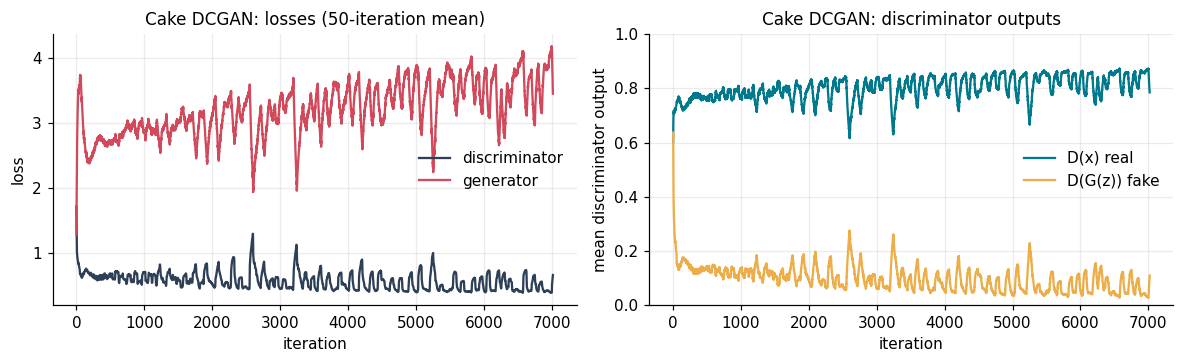

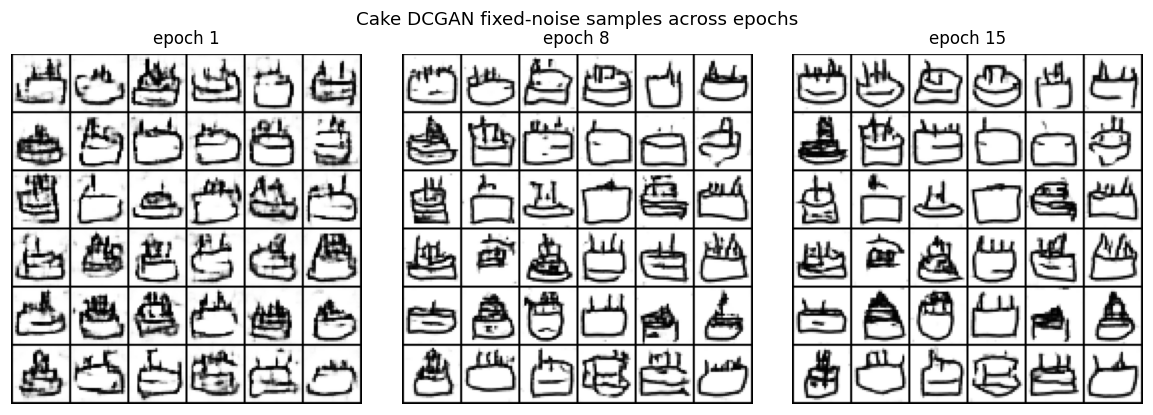

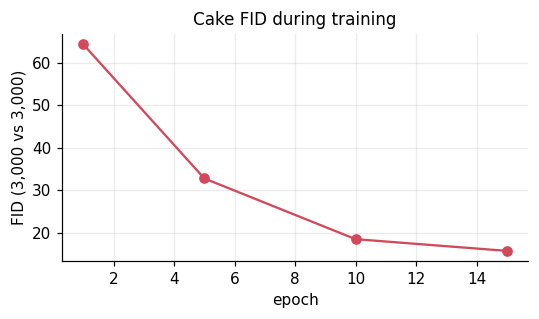

In [42]:
plot_duel_curves(cake_log, "Cake DCGAN", "qd_cake_curves")
plot_snap_progress(cake_snaps, "Cake DCGAN fixed-noise samples across epochs", "qd_cake_progress", invert=True)
fig, ax = plt.subplots(figsize=(5, 3))
ft_ = pd.DataFrame(fid_track); ax.plot(ft_.epoch, ft_.fid, "o-", color=HUE["fake"])
ax.set(xlabel="epoch", ylabel=f"FID ({CFG['qd']['n_track']:,} vs {CFG['qd']['n_track']:,})", title="Cake FID during training")
fig.tight_layout(); stamp_figure(fig, "qd_cake_fid_track")

{
 "n_each": 10000,
 "fid": 12.894012960239436,
 "fid_real_floor": 1.320669706596594,
 "kid": [
  0.009966098297915983,
  0.000703697796002071
 ],
 "kid_real_floor": [
  1.4402481197954842e-05,
  0.00011180295426024149
 ],
 "ink_fraction_real": 0.19597232142857143,
 "ink_fraction_fake": 0.19352691326530613,
 "edge_pixels_real": 138.0965,
 "edge_pixels_fake": 135.5923,
 "fid_track": [
  {
   "epoch": 1,
   "fid": 64.28966548005491
  },
  {
   "epoch": 5,
   "fid": 32.75238846001746
  },
  {
   "epoch": 10,
   "fid": 18.45632668326136
  },
  {
   "epoch": 15,
   "fid": 15.702116589770803
  }
 ]
}


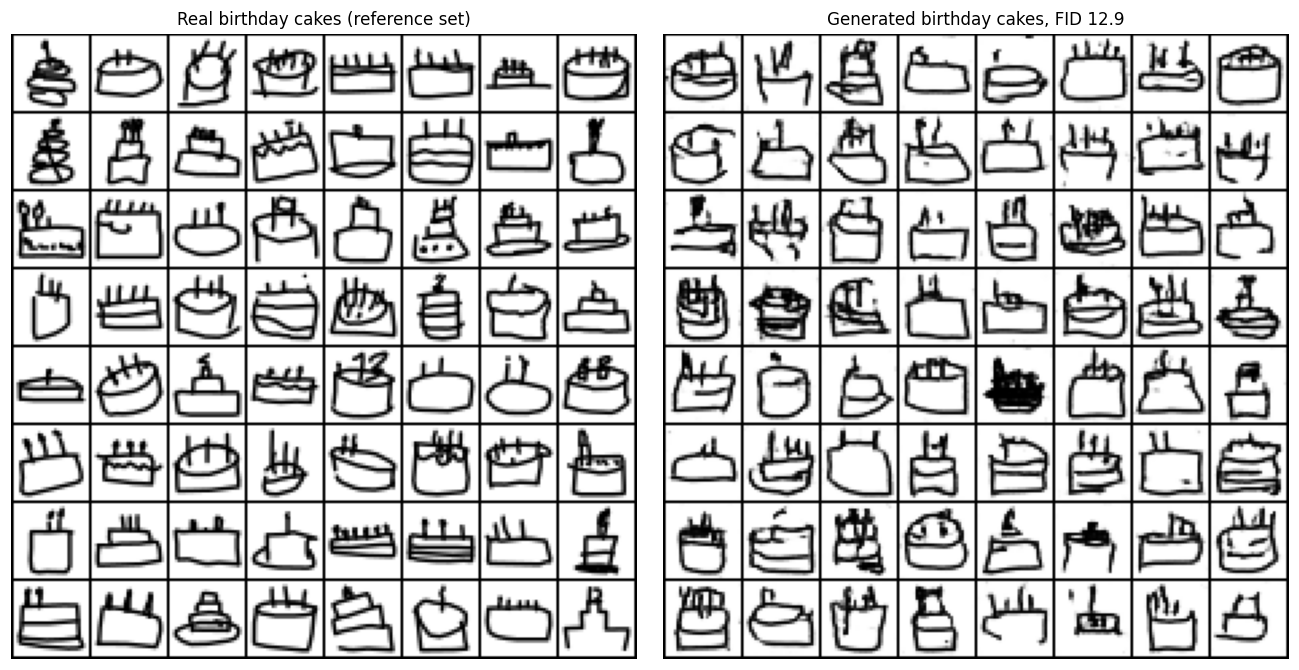

In [43]:
pin_every_seed(9)
n_ref = len(cake_ref_u8)
cake_fake = mint_images(cake_g, n_ref)
bank_cake_fake = inception_bank(cake_fake)
bank_cake_trn = inception_bank(torch.tensor(cake_tr[:n_ref])[:, None])
fk_ink, fk_edges = sketch_complexity(cake_fake[:, 0].numpy())
rl_ink, rl_edges = sketch_complexity(cake_ref)
cake_scores = {"n_each": n_ref, "fid": frechet_from_bank(bank_cake_fake, bank_cake_ref),
               "fid_real_floor": frechet_from_bank(bank_cake_trn, bank_cake_ref),
               "kid": kid_from_bank(bank_cake_fake, bank_cake_ref), "kid_real_floor": kid_from_bank(bank_cake_trn, bank_cake_ref),
               "ink_fraction_real": float(rl_ink.mean()), "ink_fraction_fake": float(fk_ink.mean()),
               "edge_pixels_real": float(rl_edges.mean()), "edge_pixels_fake": float(fk_edges.mean()),
               "fid_track": fid_track}
store_json(cake_scores, "qd_cake_metrics")
print(json.dumps(cake_scores, indent=1, default=float))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ink_grid(ax[0], cake_ref_u8[:64], title="Real birthday cakes (reference set)", invert=True)
ink_grid(ax[1], cake_fake[:64], title=f"Generated birthday cakes, FID {cake_scores['fid']:.1f}", invert=True)
fig.tight_layout(); stamp_figure(fig, "qd_cake_real_vs_fake")
del cake_x, cake_d; release_accelerator()

In [44]:
print(json.dumps({k: v for k, v in cake_scores.items()}, indent=1, default=float))
print(f"cake FID / real floor = {cake_scores['fid'] / cake_scores['fid_real_floor']:.1f}x")
_ft = {r["epoch"]: r["fid"] for r in fid_track}; _e0, _e1 = min(_ft), max(_ft)
print(f"tracked FID fell from {_ft[_e0]:.2f} (epoch {_e0}) to {_ft[_e1]:.2f} (epoch {_e1}), a drop of {1 - _ft[_e1] / _ft[_e0]:.1%}")

{
 "n_each": 10000,
 "fid": 12.894012960239436,
 "fid_real_floor": 1.320669706596594,
 "kid": [
  0.009966098297915983,
  0.000703697796002071
 ],
 "kid_real_floor": [
  1.4402481197954842e-05,
  0.00011180295426024149
 ],
 "ink_fraction_real": 0.19597232142857143,
 "ink_fraction_fake": 0.19352691326530613,
 "edge_pixels_real": 138.0965,
 "edge_pixels_fake": 135.5923,
 "fid_track": [
  {
   "epoch": 1,
   "fid": 64.28966548005491
  },
  {
   "epoch": 5,
   "fid": 32.75238846001746
  },
  {
   "epoch": 10,
   "fid": 18.45632668326136
  },
  {
   "epoch": 15,
   "fid": 15.702116589770803
  }
 ]
}
cake FID / real floor = 9.8x
tracked FID fell from 64.29 (epoch 1) to 15.70 (epoch 15), a drop of 75.6%


**Reading the birthday cake results.** The DCGAN learns the category well. FID on 10,000 against 10,000 sketches is 12.89 (real floor 1.32), and KID is 0.0100 (std 0.0007). Generated sketches match the real ink statistics closely: 19.4% of pixels carry ink, against 19.6%, and there are 135.6 edge pixels per sketch, against 138.1. FID tracked on 3,000 samples falls from 64.3 after epoch 1 to 32.8, 18.5 and 15.7 after epochs 5, 10 and 15. That is a drop of 75.6%, and the curve is still falling at the end, so a longer run would probably help, while the losses alone give no sign of this progress. Visually, the samples show the familiar cake outline with tiers and candles, with flaws in broken strokes, extra blobs of ink and candles that merge into the cake body.

### E3. Extension: star, house and cat

Three further categories span a range of drawing complexity: a star is a single closed stroke, a house combines a few straight shapes, and a cat mixes a face, ears and whiskers with large variation between drawers. Each gets a fresh DCGAN from the same builder with a smaller training set and fewer epochs. The birthday cake is rescored at the same sample size (5,000 against 5,000) so that FID values are comparable, because FID is biased by sample size (Chong and Forsyth, 2020).

In [45]:
ext_rows, ext_fakes, ext_reals = [], {}, {}
n_e = CFG["qd"]["ext_ref"]
fk_i, fk_e = sketch_complexity(cake_fake[:n_e, 0].numpy()); r_i, r_e = sketch_complexity(cake_ref[:n_e])
ext_rows.append({"category": "birthday cake", "fid_5k": frechet_from_bank(bank_cake_fake[:n_e], bank_cake_ref[:n_e]),
                 "fid_real_floor": frechet_from_bank(bank_cake_trn[:n_e], bank_cake_ref[:n_e]),
                 "ink_fraction": float(r_i.mean()), "edge_pixels": float(r_e.mean()), "ink_fraction_fake": float(fk_i.mean())})
ext_fakes["birthday cake"], ext_reals["birthday cake"] = cake_fake[:12], cake_ref_u8[:12]
for k, name in enumerate(CFG["qd"]["ext_classes"]):
    arr = fetch_sketch_category(name)
    tr, ref = split_sketches(arr, CFG["qd"]["ext_train"], n_e, seed=42 + k)
    pin_every_seed(42 + k)
    g_e, d_e = pair_conv_duelists()
    log_e, _ = duel_on_images(as_unit_tensor(tr), torch.zeros(len(tr), dtype=torch.long, device=DEVICE), g_e, d_e,
                              CFG["qd"]["ext_epochs"], seed=42 + k)
    fake_e = mint_images(g_e, n_e); ref_u8 = torch.tensor(ref)[:, None]
    b_ref, b_fake, b_trn = inception_bank(ref_u8), inception_bank(fake_e), inception_bank(torch.tensor(tr[:n_e])[:, None])
    ri, re_ = sketch_complexity(ref); fi, _ = sketch_complexity(fake_e[:, 0].numpy())
    ext_rows.append({"category": name, "fid_5k": frechet_from_bank(b_fake, b_ref), "fid_real_floor": frechet_from_bank(b_trn, b_ref),
                     "ink_fraction": float(ri.mean()), "edge_pixels": float(re_.mean()), "ink_fraction_fake": float(fi.mean()),
                     "final_loss_d": float(log_e.loss_d.tail(200).mean()), "final_loss_g": float(log_e.loss_g.tail(200).mean())})
    ext_fakes[name], ext_reals[name] = fake_e[:12], ref_u8[:12]
    del g_e, d_e; release_accelerator()
ext_table = pd.DataFrame(ext_rows); ext_table.to_csv(OUT / "qd_extension.csv", index=False)
store_json(ext_rows, "qd_extension_metrics")
ext_table.round(3)

epoch  1/10  D 0.817  G 2.402  D(x) 0.70  D(G(z)) 0.21


epoch  2/10  D 0.661  G 2.337  D(x) 0.74  D(G(z)) 0.16


epoch  3/10  D 0.625  G 2.664  D(x) 0.77  D(G(z)) 0.13


epoch  4/10  D 0.675  G 2.546  D(x) 0.75  D(G(z)) 0.15


epoch  5/10  D 0.710  G 2.680  D(x) 0.75  D(G(z)) 0.15


epoch  6/10  D 0.635  G 2.852  D(x) 0.78  D(G(z)) 0.12


... (21 outputs left out)

epoch  8/10  D 0.677  G 2.690  D(x) 0.77  D(G(z)) 0.13


epoch  9/10  D 0.633  G 2.711  D(x) 0.78  D(G(z)) 0.12


epoch 10/10  D 0.657  G 2.806  D(x) 0.77  D(G(z)) 0.12


,category,fid_5k,fid_real_floor,ink_fraction,edge_pixels,ink_fraction_fake,final_loss_d,final_loss_g
0,birthday cake,14.230,2.569,0.196,138.181,0.194,NaN,NaN
1,star,63.132,1.875,0.172,118.837,0.168,0.667,2.900
2,house,28.550,2.138,0.172,125.912,0.169,0.610,3.082
3,cat,17.556,2.266,0.198,132.440,0.206,0.642,2.827


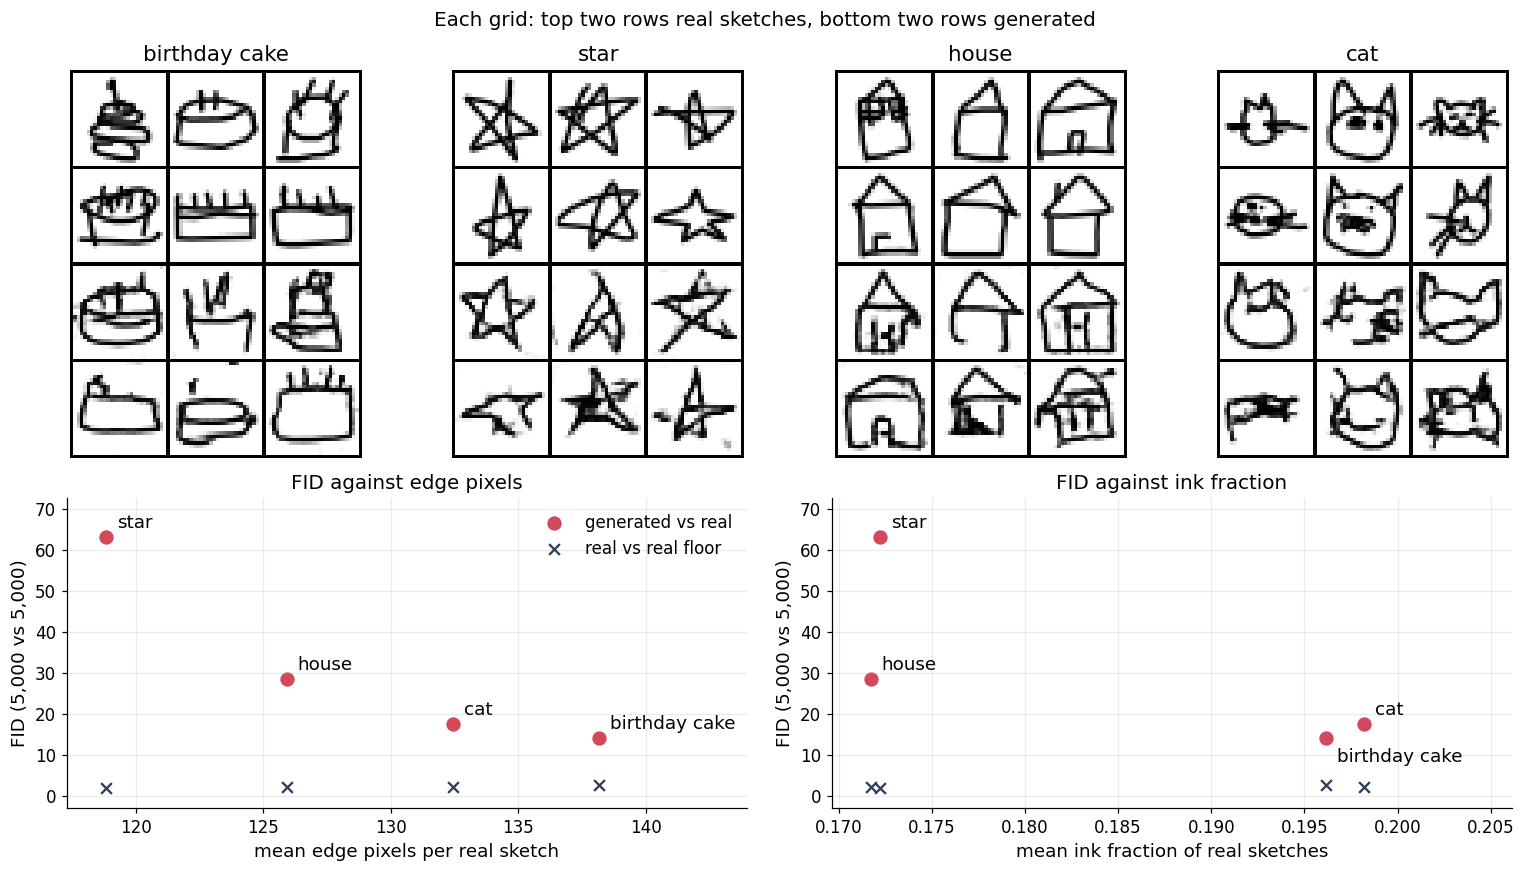

[E] 36.87 min


In [46]:
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1.25, 1])
for k, name in enumerate(ext_table.category):
    a = fig.add_subplot(gs[0, k])
    ink_grid(a, torch.cat([ext_reals[name][:6], ext_fakes[name][:6]]), nrow=3, invert=True)
    a.set_title(name, fontsize=14)
a1, a2 = fig.add_subplot(gs[1, :2]), fig.add_subplot(gs[1, 2:])
for a, col, lab, ttl in [(a1, "edge_pixels", "mean edge pixels per real sketch", "FID against edge pixels"),
                         (a2, "ink_fraction", "mean ink fraction of real sketches", "FID against ink fraction")]:
    a.scatter(ext_table[col], ext_table.fid_5k, s=70, color=HUE["fake"], label="generated vs real")
    a.scatter(ext_table[col], ext_table.fid_real_floor, s=50, marker="x", color=HUE["real"], label="real vs real floor")
    span = ext_table[col].max() - ext_table[col].min()
    a.set_xlim(ext_table[col].min() - 0.08 * span, ext_table[col].max() + 0.30 * span); a.set_ylim(-3, ext_table.fid_5k.max() * 1.15)
    for _, rw in ext_table.sort_values("fid_5k").iterrows():
        # in the ink panel the cake and cat points nearly coincide, so the lower one is labelled underneath
        below = col == "ink_fraction" and rw.category == ext_table.sort_values("fid_5k").category.iloc[0]
        a.annotate(rw.category, (rw[col], rw.fid_5k), fontsize=12, xytext=(7, -16 if below else 6), textcoords="offset points")
    a.set_xlabel(lab, fontsize=12); a.set_ylabel("FID (5,000 vs 5,000)", fontsize=12); a.set_title(ttl, fontsize=13)
    a.tick_params(labelsize=11)
a1.legend(fontsize=11, framealpha=0.9)
fig.text(0.5, 0.985, "Each grid: top two rows real sketches, bottom two rows generated", ha="center", va="top", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.965)); stamp_figure(fig, "qd_extension")
station_clock("E", t0)

In [47]:
print(ext_table.round(5).to_string())
print("fewest edge pixels:", ext_table.loc[ext_table.edge_pixels.idxmin(), "category"],
      "| lowest ink fraction:", ext_table.loc[ext_table.ink_fraction.idxmin(), "category"])

        category    fid_5k  fid_real_floor  ink_fraction  edge_pixels  ink_fraction_fake  final_loss_d  final_loss_g
0  birthday cake  14.23009         2.56918       0.19617     138.1808            0.19399           NaN           NaN
1           star  63.13189         1.87539       0.17222     118.8374            0.16768       0.66654       2.89997
2          house  28.54971         2.13785       0.17175     125.9118            0.16925       0.61047       3.08179
3            cat  17.55590         2.26613       0.19819     132.4402            0.20645       0.64216       2.82686


fewest edge pixels: star | lowest ink fraction: house


**Reading the category extension.** At 5,000 against 5,000, FID is 14.23 for the cake, 17.56 for the cat, 28.55 for the house and 63.13 for the star, with real-versus-real floors between 1.9 and 2.6. The order is the opposite of the expected one. The star has the fewest edge pixels (118.8) and, with the house, the lowest ink fraction (0.17222 against the house's 0.17175), yet it is the hardest, while the cat and cake score best. A star is defined by exact sharp geometry, so a missing or extra spike is an obvious error, while the variation in cats and cakes hides small mistakes. The cake model also had twice the data and more epochs (60,000 sketches for 15 epochs, against 30,000 for 10), which confounds the comparison. With four categories and unequal budgets, the honest conclusion is that edge count and ink coverage do not predict difficulty here. A fair test would train every category with the same budget and several seeds.

## Station F: summary of headline results

In [48]:
summary = pd.DataFrame([
    {"part": "1 sine (tutorial)", "metric": "mean |y - sin x|, seed 42", "value": sine_scores["seed_42"]["mean_abs_resid"]},
    {"part": "1 mixture", "metric": "modes covered (of 7), best variant",
     "value": variant_table[variant_table.dataset == "hex mixture"].modes_covered.max()},
    {"part": "2.1 OCT DCGAN", "metric": "Inception FID (real floor)", "value": f"{oct_scores['fid_inception']:.2f} ({oct_scores['fid_inception_real_floor']:.2f})"},
    {"part": "2.1 OCT DCGAN", "metric": "domain FID (real floor)", "value": f"{oct_scores['fid_domain']:.2f} ({oct_scores['fid_domain_real_floor']:.2f})"},
    {"part": "2.1 OCT AC-GAN", "metric": "classifier accuracy on requested class", "value": ac_scores["probe_accuracy_on_requested"]},
    {"part": "2.2 CICIDS Wednesday", "metric": "mean per-feature KS", "value": cic_scores["ks_mean"]},
    {"part": "2.2 CICIDS Wednesday", "metric": "real-vs-synthetic detector AUC", "value": cic_scores["real_vs_synth_auc"]},
    {"part": "2.2 CICIDS Wednesday", "metric": "macro F1 TRTR / TSTR", "value": f"{tstr['TRTR']['macro_f1']:.3f} / {tstr['TSTR']['macro_f1']:.3f}"},
    {"part": "2.2 CICIDS all days", "metric": "macro F1 TRTR / TSTR", "value": f"{fam_tstr['TRTR']['macro_f1']:.3f} / {fam_tstr['TSTR']['macro_f1']:.3f}"},
    {"part": "2.3 cake DCGAN", "metric": "Inception FID (real floor)", "value": f"{cake_scores['fid']:.2f} ({cake_scores['fid_real_floor']:.2f})"},
])
summary.to_csv(OUT / "summary.csv", index=False)
meta = {"smoke": SMOKE, "device": str(DEVICE), "torch": torch.__version__, "minutes_per_station": CLOCK,
        "minutes_total": round(sum(CLOCK.values()), 2)}
store_json(meta, "run_meta"); print(meta)
summary

{'smoke': False, 'device': 'mps', 'torch': '2.13.0', 'minutes_per_station': {'B': 6.23, 'C': 40.74, 'D': 42.25, 'E': 36.87}, 'minutes_total': 126.09}


,part,metric,value
0,1 sine (tutorial),"mean |y - sin x|, seed 42",0.042381
1,1 mixture,"modes covered (of 7), best variant",7.0
2,2.1 OCT DCGAN,Inception FID (real floor),31.67 (1.88)
3,2.1 OCT DCGAN,domain FID (real floor),1.58 (0.02)
4,2.1 OCT AC-GAN,classifier accuracy on requested class,0.32375
5,2.2 CICIDS Wednesday,mean per-feature KS,0.324734
6,2.2 CICIDS Wednesday,real-vs-synthetic detector AUC,1.0
7,2.2 CICIDS Wednesday,macro F1 TRTR / TSTR,0.984 / 0.774
8,2.2 CICIDS all days,macro F1 TRTR / TSTR,0.979 / 0.899
9,2.3 cake DCGAN,Inception FID (real floor),12.89 (1.32)
